<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/QP-day3/QP_Day3_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> <a href="https://kaggle.com/kernels/welcome?src=https://github.com/imguru-mooc/AI_CAMPUS/blob/main/QP-day3/QP_Day3_lecture.ipynb" target="_blank"><img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle"/></a>

# Quantization·Pruning Day 3 — PTQ 디버깅과 TensorRT INT8

**온디바이스 AI · Quantization·Pruning 3/6 · 11/18(수)** · Google Colab 또는 Kaggle · **GPU (T4)** · ONNX Runtime · TensorRT 10

어제 ResNet-20 은 INT8 로 바꿔도 정확도가 거의 그대로였습니다. 현실의 모델은 그렇지 않을 때가 많습니다. 오늘은

1. 일부러 **INT8 에서만 무너지는 모델 (BadQuantNet)** 을 받아, layer 별 오차를 재서 **범인 layer 를 찾고**, 그 layer 만 FP32 로 남기는 **mixed precision** 으로 고칩니다.
2. 양자화한 ONNX 를 **TensorRT INT8 엔진**으로 만들고, ONNX Runtime 결과와 비교합니다.
3. **YOLOv8n** 을 INT8 로 바꾸고 **mAP** 로 검증한 뒤, FP32 · FP16 · INT8 · INT8(mixed) 4개 엔진의 **배포 심사서**를 씁니다.

> **증상 확인** → **layer 별 오차 (SQNR)** → **범인만 FP32 (mixed precision)** → **TensorRT INT8 엔진** → **탐지 mAP 검증 · 배포 판단**

오늘의 목표

1. 양자화에 **민감한 layer** 의 종류와, outlier 채널 하나가 텐서 전체를 망가뜨리는 이유를 숫자로 설명할 수 있다.
2. **SQNR · cosine similarity** 를 구현하고, `qdq_loss_debug` 와 **블록별 민감도 분석**으로 원인 layer 를 지목할 수 있다.
3. `nodes_to_exclude` 로 **mixed precision** 모델을 만들고, 제외 개수와 정확도 · 속도의 trade-off 를 표로 보일 수 있다.
4. TensorRT 의 **implicit vs explicit (QDQ)** 양자화를 구분하고, TensorRT 가 받는 QDQ 조건 (**S8 대칭 · zero_point 0**) 을 점검할 수 있다.
5. INT8 엔진을 빌드해 ONNX Runtime 과 출력을 비교하고, layer 별 실행 정밀도를 확인할 수 있다.
6. YOLOv8n 을 양자화할 때 **Detect head 를 FP16 으로 두는 이유**를 설명하고, 보정 · 평가 세트를 나눠 mAP 로 검증할 수 있다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | 정확도가 떨어지는 이유 — BadQuantNet 관찰 |
| 2 | 10:00–10:50 | Layer 별 오차 분석 — SQNR · cosine · 민감도 |
| 3 | 11:00–11:50 | Mixed Precision — 범인만 FP32 로 |
| 4 | 13:00–13:50 | TensorRT INT8 개념 — implicit vs explicit (QDQ) |
| 5 | 14:00–14:50 | INT8 엔진 빌드 — FP32 · FP16 · INT8 비교 |
| 6 | 15:00–15:50 | 탐지 모델 양자화 — YOLOv8n · Detect head |
| 7 | 16:00–16:50 | 정확도 검증 — 보정 / 평가 분리 · mAP |
| 8 | 17:00–17:50 | 미니 프로젝트 — INT8 배포 심사서 · 채점 |

**노트북 사용법**

1. 아래 **0. 실행 환경 준비**대로 내 사본을 만들고 **GPU (T4)** 런타임으로 바꿉니다. 1~3 · 6 · 7교시는 CPU 로도 되지만, 4~5 · 7 · 8교시의 TensorRT 셀은 GPU 가 있어야 실행됩니다 — GPU 가 없으면 자동으로 **ONNX Runtime CPU** 로 대신 재고 표에 표시합니다.
2. **✍️ 직접 구현** 셀은 **교시마다 2문제**입니다. 문제를 보고 `# TODO` 부분을 직접 코드로 작성합니다. 확인 셀이 `✅` 를 출력하면 정답입니다. 막히면 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다.
3. **🔒 정답 보기** 셀은 **실습마다 다른 잠금 코드**로 잠겨 있습니다. 강사가 그 실습의 코드를 알려 주면 실행해 입력합니다. 정답을 연 기록은 8교시 채점 셀 결과에 함께 표시됩니다.
4. **▶ 예제 (제공 코드)** 셀은 직접 구현이 아닙니다 — 그대로 실행하고 출력 · 해설을 읽습니다. 뒤 교시가 이 셀의 함수 · 변수를 쓰므로 **건너뛰지 말고 실행**하세요.
5. **시간 숫자는 GPU · 세션마다 다릅니다.** 교안의 숫자는 강사 실측 **예시**이고, 표는 여러분이 잰 값으로 채웁니다.
6. 8교시 미니 프로젝트는 이 노트북 끝에 있습니다 (정답 셀 없음). 채점 셀 결과가 보이는 상태로 제출합니다.
7. 수업이 끝나면 **Day 3 복습 퀴즈**(HTML)를 풀고 제출합니다 — 노트북 맨 끝에 링크가 있습니다.

## 0. 실행 환경 준비 — Colab 또는 Kaggle

| 단계 | Google Colab | Kaggle |
|---|---|---|
| 열기 | 맨 위 **Open in Colab** 배지 | 맨 위 **Open in Kaggle** 배지 (또는 *File → Import Notebook* 에서 GitHub 주소 붙여넣기) |
| 내 사본 | *파일 → Drive에 사본 저장* | 열면 내 계정의 노트북으로 만들어짐 · 작업 후 **Save Version** |
| **GPU** | *런타임 → 런타임 유형 변경 → T4 GPU* | 오른쪽 패널 *Session options → Accelerator → **GPU T4 x2*** (주 30시간) |
| 인터넷 | 기본으로 켜져 있음 | *Session options → **Internet On*** (처음 한 번 **전화번호 인증**) — TensorRT 설치 · 데이터에 필요 |
| 생성형 AI | 이 노트북은 **생성형 AI 기능이 숨겨진 상태**로 배포됩니다. **다시 켜지 마세요** — 제출 파일에서 이 설정을 확인합니다. *도구 → 설정 → AI 지원* 의 **AI 기반 인라인 완성 표시** 도 꺼 두세요 | 노트북 안에 AI 자동 완성 없음 |
| 숨김 셀 | 🔒 · 🖼 · 💡 셀은 코드가 접혀 있음 | 코드가 보이지만 그대로 실행하면 됨 |

> 아래 **환경 셀**을 실행하면 `실행 환경`, GPU, 설치한 `onnxruntime` · `tensorrt` 버전이 출력됩니다. GPU 일 때 TensorRT 설치에 처음 한 번 1~2분 걸립니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html) |
| 📝 Day 3 복습 퀴즈 (수업이 끝난 뒤, 24문항) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/review_quiz.html](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/review_quiz.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/QP_Day3.pdf](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/QP_Day3.pdf) |

**오늘의 데이터 · 모델** — Day 2 의 ResNet-20 (`resnet20_cifar10.pt`), 강사가 준 **BadQuantNet** (`badquantnet.pt`), CIFAR-10 보정용 500장 · 평가용 2,000장, OT Day 5 의 **YOLOv8n** (`yolov8n.onnx`), **Penn-Fudan** 보행자 170장 (VB Day 4 와 같은 데이터). 모두 노트북이 자동으로 내려받습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, sys, re, glob, json, copy, time, shutil, urllib.request, warnings, inspect, contextlib, io, importlib.util, subprocess
from collections import Counter

# ── 실행 환경 감지 (Colab · Kaggle · 내 PC) ──
try:
    import google.colab  # noqa: F401
    PLATFORM = "Colab"
except ImportError:
    PLATFORM = "Kaggle" if ("KAGGLE_KERNEL_RUN_TYPE" in os.environ or os.path.isdir("/kaggle/working")) else "Local"
if PLATFORM == "Kaggle":
    os.chdir("/kaggle/working")

def _online(url="https://raw.githubusercontent.com", timeout=5):
    try:
        urllib.request.urlopen(url, timeout=timeout); return True
    except Exception:
        return False
ONLINE = _online()

import torch, torch.nn as nn, torch.nn.functional as F
GPU_OK = torch.cuda.is_available()

# ── 설치 (없을 때만): onnx · onnxruntime, GPU 이면 TensorRT 10 ──
_need = [p for p in ["onnx", "onnxruntime"] if importlib.util.find_spec(p) is None]
if GPU_OK and importlib.util.find_spec("tensorrt") is None:
    _need.append("tensorrt-cu12==10.16.1.11")
if _need:
    print("설치:", _need, "— 처음 한 번 1~2분")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_need], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import onnx, onnxruntime as ort
from onnx import numpy_helper
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantFormat, QuantType, CalibrationMethod
from onnxruntime.quantization.shape_inference import quant_pre_process
from onnxruntime.quantization.qdq_loss_debug import modify_model_output_intermediate_tensors, collect_activations
from IPython.display import display
try:
    import tensorrt as trt
    TRT_OK = GPU_OK
except ImportError:
    trt, TRT_OK = None, False

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 160)
torch.manual_seed(0); np.random.seed(0)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/QP-day3"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3"
EXPORT_KW = {"dynamo": False} if "dynamo" in inspect.signature(torch.onnx.export).parameters else {}
CPU = ["CPUExecutionProvider"]
BACKEND = "TensorRT" if TRT_OK else "ORT CPU"

print(f"실행 환경: {PLATFORM} | 작업 폴더: {os.getcwd()} | 인터넷: {'연결됨' if ONLINE else '끊김'} | GPU: {torch.cuda.get_device_name(0) if GPU_OK else '없음'}")
print(f"PyTorch {torch.__version__} | onnx {onnx.__version__} | onnxruntime {ort.__version__} | TensorRT {trt.__version__ if trt else '없음'}")
if not TRT_OK:
    print("⚠️ TensorRT 를 쓸 수 없습니다 — 4~8교시의 엔진 셀은 ONNX Runtime CPU 로 대신 잽니다. GPU (T4) 런타임으로 바꾸고 이 셀부터 다시 실행하면 TensorRT 로 잽니다.")

def fetch(name):
    """data/<name> 이 없으면 강의 자료 서버(GitHub Pages → GitHub 원본 순)에서 내려받는다"""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        for url in [f"{BASE}/data/{name}", f"{RAW}/data/{name}"]:
            try:
                urllib.request.urlretrieve(url, path)
                break
            except Exception as e:
                if os.path.exists(path): os.remove(path)
                print("내려받기 실패:", url, "→", e)
        else:
            raise FileNotFoundError(f"{name} 을 내려받지 못했습니다. 인터넷 연결을 확인하거나 강사에게 받은 파일을 data 폴더에 올리세요.")
    return path

@contextlib.contextmanager
def quiet():
    """양자화 도구의 긴 로그를 숨긴다"""
    with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
        yield

def size_kb(path):
    return os.path.getsize(path) / 1024

def make_session(path, threads=1):
    so = ort.SessionOptions(); so.intra_op_num_threads = threads
    return ort.InferenceSession(path, so, providers=CPU)

def bench_fn(fn, n=100, warm=10):
    """OT Day 3 · Day 2 의 bench — fn() 을 warm 번 실행한 뒤 n 번 재서 ms 통계"""
    for _ in range(warm):
        fn()
    t = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    t = np.array(t)
    return {"mean": float(t.mean()), "p95": float(np.percentile(t, 95)), "fps": float(1000 / t.mean())}

# ── TensorRT (GPU 일 때만) — OT Day 5 의 TRTInfer 그대로 ──
if TRT_OK:
    LOGGER = trt.Logger(trt.Logger.WARNING)
    RUNTIME = trt.Runtime(LOGGER)

    class TRTInfer:
        def __init__(self, engine_path):
            self.engine = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
            self.context = self.engine.create_execution_context()
            names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
            self.inputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT]
            self.outputs = [n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.OUTPUT]
            self.buf = {n: torch.empty(tuple(self.engine.get_tensor_shape(n)), dtype=torch.float32, device="cuda") for n in names}
            for n in names:
                self.context.set_tensor_address(n, self.buf[n].data_ptr())
            self.input_shape = tuple(self.engine.get_tensor_shape(self.inputs[0]))

        def __call__(self, x):
            self.buf[self.inputs[0]].copy_(torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)))
            self.context.execute_async_v3(torch.cuda.current_stream().cuda_stream)
            torch.cuda.synchronize()
            return self.buf[self.outputs[0]].cpu().numpy()

        def __repr__(self):
            return f"TRTInfer(in={self.inputs} {self.input_shape}, out={self.outputs})"

def build_once(onnx_path, engine_path, fp16=False, int8=False):
    """엔진이 이미 있으면 다시 만들지 않는다 (빌드는 수십 초 ~ 수 분). build_engine 은 4-3 에서 완성"""
    if not os.path.exists(engine_path):
        t0 = time.time(); build_engine(onnx_path, engine_path, fp16=fp16, int8=int8)
        print(f"빌드 {engine_path} — {time.time() - t0:.0f} 초")
    return engine_path

import hashlib, base64, datetime
_HINT_N = {}
def show_hint(no, blob):
    # 💡 실행할 때마다 힌트를 하나씩 더 보여 준다
    hints = base64.b64decode(blob).decode("utf-8").split("\x1e")
    k = min(_HINT_N.get(no, 0) + 1, len(hints)); _HINT_N[no] = k
    for i in range(k):
        print(f"💡 힌트 {i + 1}/{len(hints)} — {hints[i]}")
    print("(다시 실행하면 다음 힌트)" if k < len(hints) else "(힌트를 모두 봤습니다 — 이제 직접 구현해 보세요)")

def show_answer(no, blob):
    # 🔒 잠금된 정답 보기 — 강사가 알려 준 '실습별' 잠금 코드가 있어야 열린다
    raw = base64.b64decode(blob); tag, body = raw[:8], raw[8:]
    for _ in range(2):
        code = input(f"🔒 실습 {no} 잠금 코드: ").strip().upper()
        ks, i = b"", 0
        while len(ks) < len(body):
            ks += hashlib.sha256(f"{code}|qp-day3|{no}|{i}".encode()).digest(); i += 1
        plain = bytes(a ^ b for a, b in zip(body, ks))
        if hashlib.sha256(plain).digest()[:8] == tag:
            with open(".qp_answer_log", "a") as f:
                f.write(f"{no}\t{datetime.datetime.now():%H:%M}\n")
            print(plain.decode("utf-8")); return
        if not code: break
    print("❌ 잠금 코드가 맞지 않습니다. 강사가 이 실습의 코드를 공개하면 다시 실행하세요.")

In [ ]:
# ▶ 데이터 · 모델 셀 (1) — CIFAR-10 · ResNet-20 · BadQuantNet · Day 2 함수
MEAN = np.array((0.4914, 0.4822, 0.4465), np.float32)
STD = np.array((0.2470, 0.2435, 0.2616), np.float32)
cal, ev = np.load(fetch("cifar_calib.npz")), np.load(fetch("cifar_eval.npz"))

def preprocess(images):
    x = images.astype(np.float32) / 255.0
    return ((x - MEAN) / STD).transpose(0, 3, 1, 2).copy()

X_cal, X_ev, y_ev = preprocess(cal["images"]), preprocess(ev["images"]), ev["labels"]

class BasicBlock(nn.Module):                      # VB Day 2 · QP Day 2 와 같은 구조
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False); self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
                         if stride != 1 or cin != cout else nn.Identity())

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))

class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = nn.Sequential(*[BasicBlock(16, 16) for _ in range(n)])
        self.layer2 = nn.Sequential(BasicBlock(16, 32, 2), *[BasicBlock(32, 32) for _ in range(n - 1)])
        self.layer3 = nn.Sequential(BasicBlock(32, 64, 2), *[BasicBlock(64, 64) for _ in range(n - 1)])
        self.pool = nn.AdaptiveAvgPool2d(1); self.fc = nn.Linear(64, n_cls)

    def forward(self, x):
        x = self.layer3(self.layer2(self.layer1(self.stem(x))))
        return self.fc(self.pool(x).flatten(1))

def load_resnet(name):
    m = ResNet(); m.load_state_dict(torch.load(fetch(name), map_location="cpu")); return m.eval()

rn20, bad = load_resnet("resnet20_cifar10.pt"), load_resnet("badquantnet.pt")

def export_onnx(model, path, batch=None):
    """batch=None 이면 배치 가변 (ONNX Runtime 용), 숫자면 고정 (TensorRT 엔진용)"""
    dyn = None if batch else {"input": {0: "N"}, "logits": {0: "N"}}
    torch.onnx.export(model, torch.zeros(batch or 1, 3, 32, 32), path, input_names=["input"], output_names=["logits"],
                      dynamic_axes=dyn, opset_version=17, **EXPORT_KW)
    return path

class CifarReader(CalibrationDataReader):        # Day 2 실습 4-1
    def __init__(self, X, bs=50):
        self.batches = [X[i:i + bs] for i in range(0, len(X), bs)]; self.rewind()
    def get_next(self):
        b = next(self.it, None)
        return None if b is None else {"input": b}
    def rewind(self):
        self.it = iter(self.batches)

def ort_acc(path, X=None, y=None, bs=250):       # Day 2 실습 1-3
    X = X_ev if X is None else X; y = y_ev if y is None else y
    s = ort.InferenceSession(path, providers=CPU)
    preds = [s.run(None, {"input": X[i:i + bs]})[0].argmax(1) for i in range(0, len(X), bs)]
    return float((np.concatenate(preds) == y).mean())

def ptq_ort(src, dst, exclude=(), quantize=None, X=None):
    """Day 2 의 static PTQ 설정 그대로 (QDQ · 활성값 U8 · weight S8 · per-channel · MinMax)"""
    with quiet():
        quantize_static(src, dst, CifarReader(X_cal if X is None else X), quant_format=QuantFormat.QDQ,
                        activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, per_channel=True,
                        nodes_to_exclude=list(exclude), nodes_to_quantize=quantize)
    return dst

print("보정용", X_cal.shape, "| 평가용", X_ev.shape, "| ResNet-20 · BadQuantNet 파라미터", sum(p.numel() for p in bad.parameters()))

## 1교시 — 정확도가 떨어지는 이유: BadQuantNet 관찰

### 양자화에 민감한 곳

| 위치 | 왜 민감한가 | 흔한 대처 |
|---|---|---|
| **첫 Conv** | 입력 이미지의 정보를 처음 줄이는 곳 · 채널이 3개뿐이라 오차가 그대로 전파 | FP16 유지 |
| **마지막 분류기 · 탐지 head** | 출력 범위가 서로 다른 값(박스 좌표 0~640 · 점수 0~1)을 한 텐서에 담음 | FP16 유지 (6교시) |
| **depthwise Conv** | 채널마다 weight 가 몇 개뿐 → 채널 간 범위 차이가 큼 | per-channel 필수 |
| **SiLU · Hardswish 뒤** | 음수 쪽 꼬리가 있는 비대칭 분포 | 비대칭 · 보정 방법 |
| **outlier 채널** | 채널 하나의 값이 수백 배 → **텐서 전체 scale** 이 그 채널에 맞춰짐 | 범인 layer FP32 · 채널 균등화 |

그리고 오차는 **누적**됩니다. 앞에서 생긴 오차가 다음 layer 의 입력이 되어 뒤로 갈수록 커집니다.

> 🎬 **애니메이션** [D3-1 outlier 채널 찾기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-1)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

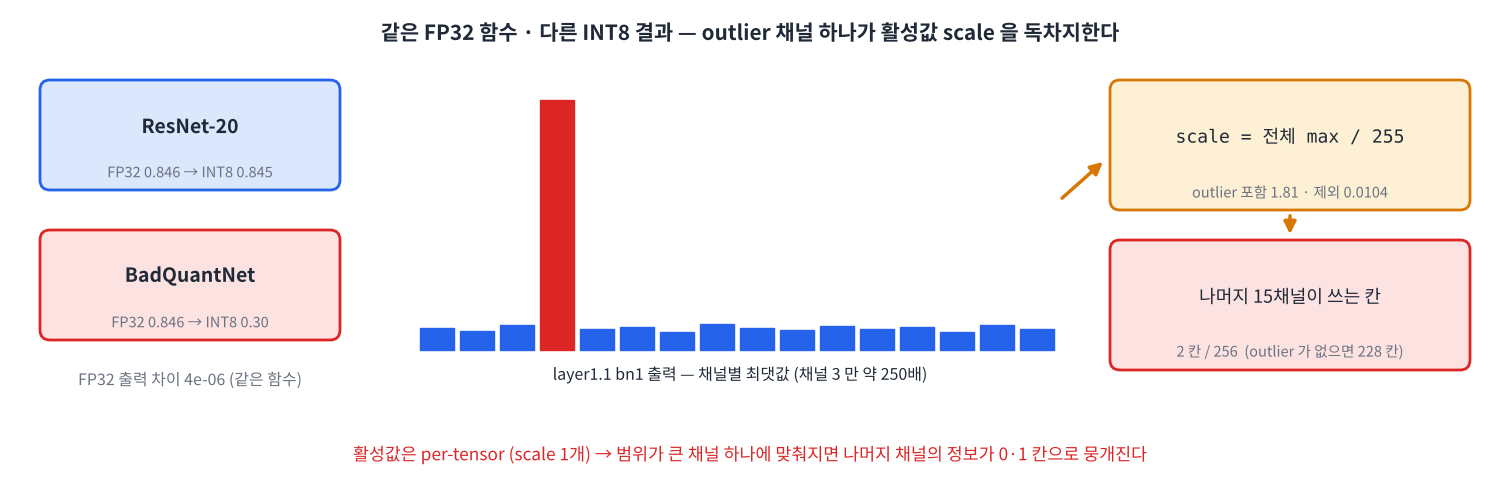

In [ ]:
#@title 🖼 그림 — 같은 FP32 함수 · 다른 INT8 결과 — outlier 채널 하나가 텐서 scale 을 독차지한다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f1_sensitive.png", embed=True, width=860))

강사가 준 **BadQuantNet** 은 ResNet-20 과 구조가 같습니다. 먼저 두 모델을 Day 2 와 **똑같은 설정**으로 INT8 로 바꿔 봅니다.

**✍️ 직접 구현 1-1** `rn20` 과 `bad` 를 각각 `rn20.onnx` · `bad.onnx` 로 내보내고 (`export_onnx`), `quant_pre_process` → `*_pre.onnx`, `ptq_ort` 로 `*_int8.onnx` 를 만드세요. 두 모델의 FP32 · INT8 정확도를 `cmp_df` (열 `model`, `fp32`, `int8`) 로 정리합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 1-1 — 실행할 때마다 하나씩
show_hint("1-1", "65GQIOuqqOuNuOydhCBgZm9yIG5hbWUsIG0gaW4gWygicm4yMCIsIHJuMjApLCAoImJhZCIsIGJhZCldOmAg66GcIOqwmeydgCDsiJzshJzroZwg7LKY66as7ZWY66m0IOy9lOuTnOqwgCDrsJjsnLzroZwg7KSE7Ja065Ot64uI64ukLh7siJzshJw6IGBleHBvcnRfb25ueChtLCBmIntuYW1lfS5vbm54IilgIOKGkiBgd2l0aCBxdWlldCgpOiBxdWFudF9wcmVfcHJvY2VzcyjsnoXroKUsIGYie25hbWV9X3ByZS5vbm54IilgIOKGkiBgcHRxX29ydChmIntuYW1lfV9wcmUub25ueCIsIGYie25hbWV9X2ludDgub25ueCIpYC4eRlAzMiDsoJXtmZXrj4TripQgYCpfcHJlLm9ubnhgLCBJTlQ4IOydgCBgKl9pbnQ4Lm9ubnhgIOulvCBgb3J0X2FjY2Ag66GcLiDtlokg7IKs7KCE7J2EIOumrOyKpO2KuOyXkCDrqqjslYQgYHBkLkRhdGFGcmFtZShyb3dzKWAu")

In [ ]:
# ✍️ 직접 구현 1-1 — 두 모델을 Day 2 설정으로 INT8 로 바꾸고 정확도 비교
rows = []
# TODO: rn20 · bad 각각 export → quant_pre_process → ptq_ort → 정확도 2개
cmp_df = None   # TODO: 열 model, fp32, int8

display(cmp_df)

In [ ]:
r_, b_ = cmp_df.set_index("model").loc["rn20"], cmp_df.set_index("model").loc["bad"]
assert abs(r_.fp32 - b_.fp32) < 0.001 and r_.int8 > r_.fp32 - 0.01 and b_.int8 < 0.5
print(f"✅ FP32 는 둘 다 {r_.fp32:.3f} — INT8 은 ResNet-20 {r_.int8:.3f} · BadQuantNet {b_.int8:.3f}")

In [ ]:
#@title 🔒 정답 보기 1-1 — 강사가 알려 준 실습 1-1 잠금 코드를 입력하세요
show_answer("1-1", (
    "g+syQtSwKNi5eBuT9X32TlV/s4jN6OZuii1vomYRvORFvxuazJNWcT6AZgq2h9nPdjzFkNkL1gzXaZsJE8X58nlV"
    "outlj95F4V6GWfkHuuxRq1XP/TgEQMazc25vmxbaNrXCguWJGn109LTFxK6f8QbAuVJXi+BXRDJSgPjZCc+Q01lC"
    "VzrCHPnQ2h6ALymShQnkinkCylpEw4m/EVUBzSIMncmUuDdZKsDDsElSnRcOzjXj5KPyLo/tm+KFg9iRhGJQgCy4"
    "73OEjTwFQ9zOifvVv906VAS/0fbePeyiqiPp9UvyJMNolIqz7qeQWS7adtWWqvFztDyQb8JlrN7hJF2gmrXSIOcW"
    "doX6dNqbLrJjIenCVZ0VlRvr43LxJmMeRgWL27eq53zH3cUdiA0L7oLMJi4X5BqmHwfHhZp2AIDHFc/IhZ423Y0U"
    "NVybJd3NLgnSQrv8brSZKn/NSvqs2hGJyQoWHQzXX/YH1m25+ctxv7AmPWQYSqmp3HomAtyOgJHETD6BZyoBT1ub"
    "ejl7osYMzrLzcJYZfZOHql4566cvj3w58WioA7VLI55386dL7ZeOLZGm/9kue8+S5fNxEyCGZ0PA/cQ1SV2XZ2cY"
    "a4DfrFkTm/OjX3oY3Fu7dktTjxCMvJx8PM7sgHpctJD7gCVI3lj3tFc5GDWbNkMesY1lwy6tsbAQA76LL+BFv/fL"
    "3jhUX23P4UOoEM4np2vbhIode90A2d2fGiJu/++Qtqd4ShWvSJBukf3uLIzjx1bk52vIoVarASnlfAbSC5pZfGi3"
    "qZQW5zhdSKQ5O0B8mzLMDpzPx9dpxulBVdNDQYQ0T99pbKsLlVyPqcZiMgCUxLaJpcVMfr9sbWROoEHIz0hXd9PT"
    "12ZutTunI8SAiwTDx4+UQCOFV1IiMBL1e1k//ifImUne"
))


**✍️ 직접 구현 1-2** PyTorch 로 두 모델의 출력 차이를 재 보면 FP32 에서는 **같은 함수**입니다. 그렇다면 무엇이 다를까요? 각 블록의 `bn1` 출력(ReLU 직전)에 **forward hook** 을 걸어 보정용 100장을 흘리고, 블록마다 **채널별 최댓값(절댓값)** 의 `최댓값 / 중앙값` 비율을 구해 `ratio_df` (열 `block`, `ratio`, `channel`) 를 만드세요. `acts` 사전에 블록 이름 → bn1 출력 (numpy) 을 저장해 둡니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 1-2 — 실행할 때마다 하나씩
show_hint("1-2", "RlAzMiDruYTqtZA6IGBybjIwKHRvcmNoLmZyb21fbnVtcHkoWF9ldls6MjAwXSkpYCDsmYAgYGJhZCguLi4pYCDsnZgg7LCo7J20IOygiOuMk+qwkiDstZzrjIAgKGB0b3JjaC5ub19ncmFkKClgIOyViOyXkOyEnCkuHmhvb2s6IGBtb2QuYm4xLnJlZ2lzdGVyX2ZvcndhcmRfaG9vayhsYW1iZGEgbV8sIGlucCwgb3V0LCBuYW1lPW5hbWU6IGFjdHMuX19zZXRpdGVtX18obmFtZSwgb3V0LmRldGFjaCgpLm51bXB5KCkpKWAg4oCUIGBpc2luc3RhbmNlKG1vZCwgQmFzaWNCbG9jaylgIOyduCDrqqjrk4jrp4jri6QuHuuztOygleyaqSAxMDDsnqXsnYQg7ZWcIOuyiCDtnZjrprAg65KkIGBoLnJlbW92ZSgpYCDroZwgaG9vayDsnYQg6rytIOyngOybgeuLiOuLpC4e7LGE64SQ67OEIOy1nOuMk+qwkjogYG5wLmFicyhhKS5tYXgoYXhpcz0oMCwgMiwgMykpYCDihpIg67mE7JyoID0gbWF4IC8gYG5wLm1lZGlhbmAsIOyxhOuEkCA9IGFyZ21heC4=")

In [ ]:
# ✍️ 직접 구현 1-2 — FP32 차이 fp32_diff, 블록별 bn1 출력 acts, outlier 비율 ratio_df
fp32_diff = None   # TODO
acts = {}
# TODO: 각 BasicBlock 의 bn1 에 forward hook → X_cal[:100] 흘리기 → hook 제거
ratio_df = None    # TODO: 열 block, ratio, channel

print(f"FP32 출력 최대 차이 {fp32_diff:.1e}")
display(ratio_df.round(1))

In [ ]:
top3 = set(ratio_df.sort_values("ratio").block.tail(3))
assert fp32_diff < 1e-3 and top3 == {"layer1.1", "layer2.1", "layer3.1"} and ratio_df.ratio.max() > 100 and len(acts) == 9
print("✅ FP32 함수는 같다 — 블록 3개에 다른 채널보다 수백 배 큰 outlier 채널 (", sorted(top3), ")")

In [ ]:
#@title 🔒 정답 보기 1-2 — 강사가 알려 준 실습 1-2 잠금 코드를 입력하세요
show_answer("1-2", (
    "nCtZFZLhMGyTzRTgj7AHqx6b+UbPCOhUcoa38TUv0NpSlXFBDYKSAd5ggRUJLJMN6WOlMCDP3uY4m7bxjWLt3sJ4"
    "mSC77QPUucnxuoeaO7MD3+gXO1wFPQeScPjud2ZUwvD+Eswu5ebxMS9MAlVaTHi7Aoz1UtYegfZLNxnNgjDX6frJ"
    "9xDFQNz0B2iBTkQb3+cVdrjb091LOroTs3A/odhpjjigFRWaYVHaHB0er97ZUni0sc5Ij70b66pomO1RiZqNW0sd"
    "N+4PFq+aZeX+4y6ZJncMGK/QIbEO7bnIQWKdfkkPo0USHGOsKxqVlPh8bWdlRT8vVJNO99vY0tRa83KjIDNks1QR"
    "aZrqvg1lXBUlnA3Ls8U7TH+1PccIPcY1zk2QQoRsYBd7WT45X7iPL08n6Jj4jGceHs4xW3+ldYuPANvZkEL4/SBo"
    "Mm2uTEdwfp1KqVfuyUsvGUxKMfQ/geDCpN9aUzuye76KkHpyLif1w65GiJP/78yiJEk9hFNrwbgZILkWiPR0OxbB"
    "/5kgbYnbOb6pRmXmnXU+++lM59WElP5HMaClwMdaLCLvycE2+OEIGbw6s6LpwjY1OZpNK+0DncxRqZELv/eeSPP7"
    "DOQ+9seP5cVym4bcLkPs8jADDXofStk3CB576kWMyHS6CgcT1IwmEPgTFkO9XPCdqoosKhuar86GwaAc0/GiXng8"
    "U1SJWKBampahUKpSbclRQRAkn0O18rB8nKn0t2F3EOrKfILF/ZSawNqCzodYCMG2zA8u8+zBaQYVNqlcvUBCl8nz"
    "SJuT4aEMnXeQ81pDk0c1e5Ba5jVU6p16ygYd1Ee1drs4GLdUyZaulIIRungM4dC8u2jmVuV97UCanRDu1jrNpdnR"
    "VhMcDUFxQStcpVWuYiQ/LhRAx7V1llIjRL3OcLs8rPF5ChDy3Nfj4jErfY+hWBJb5mvfMuWJOip3gA/ojXyI6QGs"
    "pFwX6LBkagIl0C5qD19WABw9+4CDXAymtMltnzEU4/piTEw2Tx6TrAKRWITV6LOXUhPIXbne+T6jP/9a7+n8hvgc"
    "nrv2S6XmZDkQJhjeY7VLLgK8vKCjLcr/BOQWfgrJXfEsOnRoXpEZnR3X3mBP8LDLOTGyB6U7qLgsVIN0+wOdD5/Y"
    "Ue/i8rTdpu51lpZuWzYzbuOLP0tlwKx6D8ByDeIyriCTQ7blPcYpUWncKjz3yDeo6HNIXKWOK/ycNurg8kPbPs/Q"
    "YOnMJJjAZyL1Z7VbNswVZjudQqOH5dRiGjPMuwc6vDYqIz4CFARoXdbgY3+hOU8nEvs6IXM4JY3FcJCAJ6V00mOB"
    "hXMBhLF+hAsLYkO17+fZraQKS0hthkkFOw8VbemueHy++4u1gCqBy2sAhFiND/tuwwGFAjMeCI71fcdnj5sdnOhQ"
    "ZJEgJhITgm574v7OOE9z0htq9c6tNnyiOZfiH59z3lfgBmmEBXsRQbmFuMsUcpuGfiWvk7pxxbhZ4N2GOkoV6Xiy"
    "9+QGA6Se4PgPAfx6YcGhon9pk+27xh5jJ5NBHQQXrunFLEdDBylHCz4+BOZ7cK0ofECsdONaVus0xf5dwQv1Ys/0"
    "pRh0Mu6r8Ji2MzzpHYm4JWL4oZtz0RzQ9nEaqm7D+l99Hn7nA0oLP/MsyyIkWazsG3umEgTEG5OyAopm/snTvar2"
    "7jMHqf6HR2jEl4sensn84KyJTB/VtvunB/Cd8MdMadcFFayAtjQEzwXmlYfBn0Add6mj3fFeDkrMA6nqMEUxx6pV"
    "ey2Xror+phI+lNm4QIobC5PSPD+VtCsxmPvasYJCQgwirCfzSUrIzjBxQC9a7pYIF6xSjVaJTEuKWjlJgeAFRjqd"
    "LjDAilHAzqrltJeg5kURrQ=="
))


**▶ 예제 1-A (제공 코드 — 실행만)** outlier 채널이 왜 문제일까요? `layer1.1` 의 bn1 출력에 ReLU 를 적용한 `A` 를 **텐서 하나의 UINT8 scale (per-tensor, 0 ~ max)** 로 양자화할 때, outlier 채널(1-2 의 `channel`)을 **뺀 나머지 채널**이 실제로 쓰는 정수 칸 수 `levels_all` 을 셉니다. 같은 나머지 채널을 그 채널들의 최댓값으로 scale 을 잡았을 때의 칸 수 `levels_wo` 와 비교합니다. 실행 전에 예측해 보세요 — 256칸 중 몇 칸을 쓸까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 1-A — 제공 코드 (그대로 실행)
A = np.maximum(acts["layer1.1"], 0)
ch = int(ratio_df.set_index("block").loc["layer1.1", "channel"])
normal = np.delete(A, ch, axis=1)                              # outlier 채널을 뺀 나머지
s_all = A.max() / 255                                          # 텐서 전체 범위로 잡은 scale
s_wo = normal.max() / 255                                      # outlier 가 없을 때의 scale
levels_all = len(np.unique(np.round(normal / s_all)))
levels_wo = len(np.unique(np.round(normal / s_wo)))
print(f"scale {s_all:.4f} (outlier 포함) vs {s_wo:.4f} (제외) — 나머지 채널이 쓰는 칸 {levels_all} 개 vs {levels_wo} 개 / 256")

In [ ]:
assert s_all > 50 * s_wo and levels_all <= 5 and levels_wo > 100
print(f"✅ outlier 채널 하나 때문에 나머지 15개 채널이 256칸 중 {levels_all}칸만 쓴다")

> 💡 **예제 1-A 해설** — 활성값은 per-tensor 로 양자화되므로 scale 이 가장 큰 채널(1.8)에 맞춰집니다. 나머지 채널의 값(최대 약 2.7)은 0 또는 1 칸으로 뭉개져 정보가 거의 사라집니다. Day 1 5교시의 '튀는 필터 하나' 가 weight 에서 일어난 일이라면, 이것은 활성값에서 같은 일이 일어난 것입니다. 활성값은 per-channel 로 바꿀 수 없어서 더 위험합니다.

#### 📌 1교시 정리

- 같은 FP32 함수라도 **중간 텐서의 범위**가 다르면 INT8 결과가 크게 다르다 (BadQuantNet 0.846 → 약 0.30).
- 활성값은 **per-tensor** — outlier 채널 하나가 scale 을 독차지하면 다른 채널은 몇 칸만 쓴다 (2칸 vs 228칸).
- 문제는 '모델 전체' 가 아니라 **특정 layer** 에 있다 → 2교시에 그 layer 를 숫자로 찾는다.

## 2교시 — Layer 별 오차 분석: SQNR · cosine · 민감도

두 텐서가 얼마나 비슷한지 재는 두 가지 지표를 씁니다.

| 지표 | 식 | 읽는 법 |
|---|---|---|
| **SQNR** (Signal-to-Quantization-Noise Ratio) | 20 · log10( ‖x‖ / ‖x − x̂‖ ) dB | 클수록 좋음. 8비트 이상적 양자화 ≈ 40 dB 안팎 · **20 dB 아래면 의심** · 0 dB 근처면 신호만큼 오차 |
| **cosine similarity** | x · x̂ / (‖x‖ ‖x̂‖) | 1 에 가까울수록 같은 방향. 0.99 아래로 떨어지면 의심 |

layer 를 찾는 두 가지 방법:

1. **누적 비교** — FP32 모델과 INT8 모델을 끝까지 실행하고 같은 위치의 중간 텐서를 비교 (`qdq_loss_debug`). 오차가 **어디서부터 커지는지** 보이지만, 앞에서 무너지면 뒤는 모두 나빠 보입니다.
2. **단독 민감도** — 블록 **하나만** 양자화하고 나머지는 FP32 로 둔 모델을 블록마다 만들어 최종 출력을 비교. 블록의 **자기 책임**만 보입니다.

> 🎬 **애니메이션** [D3-2 SQNR 과 민감도](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-2)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

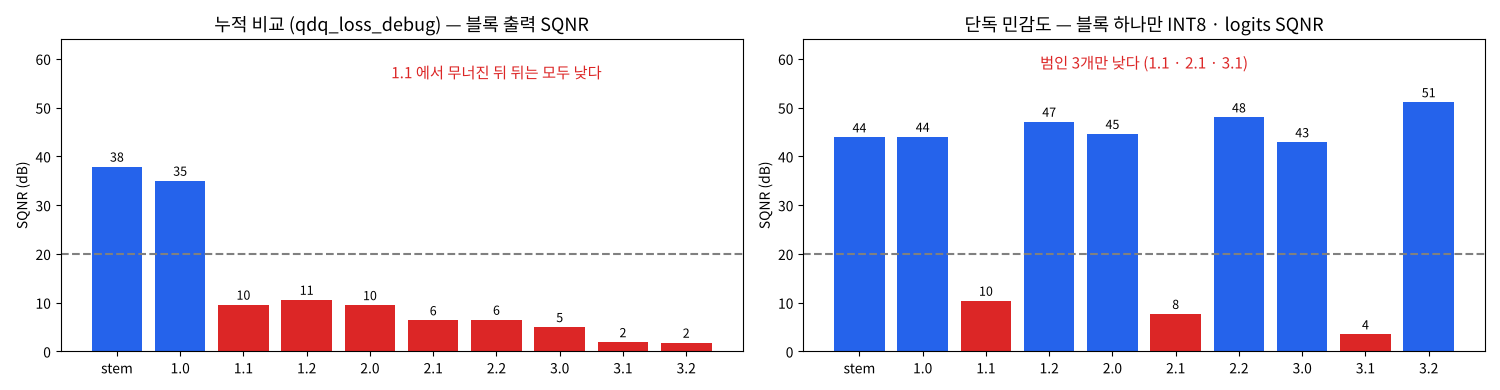

In [ ]:
#@title 🖼 그림 — 누적 비교 vs 단독 민감도 — 앞에서 무너지면 뒤는 다 나빠 보인다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f2_sqnr.png", embed=True, width=860))

**✍️ 직접 구현 2-1** 두 배열(모양 무관)을 받아 **SQNR (dB)** 과 **cosine similarity** 를 돌려주는 `sqnr(x, y)`, `cosine(x, y)` 를 만드세요. 둘 다 1차원으로 펴서 계산하고, 0 으로 나누지 않게 분모에 `1e-12` 를 더합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 2-1 — 실행할 때마다 하나씩
show_hint("2-1", "66i87KCAIGBucC5yYXZlbCh4KS5hc3R5cGUobnAuZmxvYXQ2NClgIOuhnCAx7LCo7JuQIMK3IDY067mE7Yq466GcLh5TUU5SID0gYDIwICogbnAubG9nMTAobnAubGluYWxnLm5vcm0oeCkgLyAobnAubGluYWxnLm5vcm0oeCAtIHkpICsgMWUtMTIpKWAuHmNvc2luZSA9IGB4IEAgeSAvIChucC5saW5hbGcubm9ybSh4KSAqIG5wLmxpbmFsZy5ub3JtKHkpICsgMWUtMTIpYC4g65GYIOuLpCBmbG9hdCDroZwg64+M66Ck7KSN64uI64ukLg==")

In [ ]:
# ✍️ 직접 구현 2-1 — 두 지표
def sqnr(x, y):
    # TODO
    pass

def cosine(x, y):
    # TODO
    pass

x = np.random.randn(1000)
print(f"오차 1% → SQNR {sqnr(x, x * 1.01):.1f} dB | 노이즈 10% → {sqnr(x, x + 0.1 * np.random.randn(1000)):.1f} dB | 부호 반대 cos {cosine(x, -x):.2f}")

In [ ]:
_x = np.arange(1, 11, dtype=np.float64).reshape(2, 5)
assert abs(sqnr(_x, _x * 1.01) - 40.0) < 1e-3 and abs(cosine(_x, -_x) + 1) < 1e-9 and abs(cosine(_x, 3 * _x) - 1) < 1e-9 and sqnr(_x, _x) > 200
print("✅ 1% 오차 = 40 dB · 크기만 다르면 cos = 1 · 반대 방향이면 −1")

In [ ]:
#@title 🔒 정답 보기 2-1 — 강사가 알려 준 실습 2-1 잠금 코드를 입력하세요
show_answer("2-1", (
    "zQUdtiQt4XH7/GctHZkq9w/uXwv78iINSiSHf3UN+t7B1BwcoAeXkmVtUs3qdliGig7mNDl9r3I5RaisKAp3oM7I"
    "kquCz0ImfpNG27oOUVPGrNLpU7f9MW4rdFLLkwh28roOAiISvuRkwU5hBHHctAhdtWSEyuO0Ws00LZOxGpOy8H7i"
    "JF5cAHx5EZMnTJzJHkUxpPUN/DiVWEt/aS+oQx/sBg6J2kW0NHdtCZVfardux0H8b6GKRZzC1y+1cC/9EmrS/Y5g"
    "g/7uqt7NbQRze9B4U9G94iiEJ2idv3dmWFm/DWNDAxn2gWhaSfQ9feZlIZfusCT5zYc8xS5WtF0qaO3pGI06xvJd"
    "ZSOOxNYvwKy2CPE6ik+8BBqwXu2/wuUWeflfAcND4boVAXMUsD2zol7dShPDQwEOamVVO9XuakLL/hx2Yp9c2EOa"
    "9ZO5HNW1OUXOSUE2bQs3v+s09XObgDoKdt5pmAcKYtqlXeo6395PocIdMSZpPY8tBqW6s338AKIVb9pzcCuRNILa"
    "908xLcWRs/eBwCUsw4vxSSFcheBCRDuF9/vWyLS8LhO2VwjqJnZ3PMln69hhv20Kaci7nBX10Y4G6/sQ8y2O/now"
    "y2R5+oY+ApYPfwCIHzKw+lglysD0YdvsdnrtkpVwgwHgKsWN+KpRc9DgpWciQ48PIQ83lHrYvlMHOiUgHNfZ/+yd"
    "Jio/UJmpqZAiwT+EUVKhH8OxZcFue5h5gEcyVGZ+jz+ypQ2/drapzwH3ZDax8SD7ib23Qvu6BsiQrNUxpBaJwyKM"
    "xK35K/56Ir/obZhTquMBKIyMHVNZPjC5w0JWA2C4JkvTv6/nFUhr+f5295H34qZpdN/FdQENsWUEtZO8eqgt/GF5"
    "GZjnYZQRbEskVqZg6VLNtzP0+WUT5Outp88qMycCLvGYproINLbfMfLXJScLATagWlZhTb1uETisSkgtphTB9eC5"
    "tMQxVZ/6GA9ugJXaRAQFFJYrLIr6DRYNZfjSK0IsycHZB2L0+7ydx813X6FEL1sKMOSFFUQJp8snZLx9to/euMdy"
    "nNJS3keUvHLv7EsXOuzOipXT+H0S8oM4ik/vSNM81UvMgYGLRRIKoCPxW1e92YWgkQFTPYuIICxrp//tQHMYZmwp"
    "+B4wV2L8ufeTXYHxuh8oHVJA09rxG/jIUXYtlgq6CdOrsTG7CGACiuiS"
))


`qdq_loss_debug` 는 모델의 **모든 중간 텐서를 출력으로 꺼내는** 모델을 만들고 (`modify_model_output_intermediate_tensors`), 데이터를 흘려 그 값을 모아 줍니다 (`collect_activations`). FP32 모델과 INT8 모델에서 각각 모으면 같은 이름의 텐서끼리 비교할 수 있습니다. 블록 출력 텐서 이름은 `/layer1/layer1.0/Relu_1_output_0` 처럼 생겼습니다. INT8 모델에서는 같은 이름 뒤에 `_DequantizeLinear_Output` 이 붙은 텐서가 **양자화 → 역양자화를 거친 값** — 실제로 다음 layer 가 받는 값입니다.

**▶ 예제 2-A (제공 코드 — 실행만) · 누적 비교** `bad_pre.onnx` 와 `bad_int8.onnx` 의 중간 텐서를 보정용 100장으로 모아, **stem 출력과 블록 9개의 출력**에서 FP32 대비 INT8 의 SQNR · cosine 을 구해 `blk_df` (열 `block`, `sqnr`, `cos`, 순서대로 10행) 를 만듭니다 — 2-1 에서 만든 `sqnr` · `cosine` 을 그대로 씁니다. 직전보다 SQNR 이 가장 많이 떨어진 블록 `first_drop` 도 찾습니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 2-A — 제공 코드 (그대로 실행)
modify_model_output_intermediate_tensors("bad_pre.onnx", "bad_aug_f.onnx")
modify_model_output_intermediate_tensors("bad_int8.onnx", "bad_aug_q.onnx")
with quiet():
    f_acts = collect_activations("bad_aug_f.onnx", CifarReader(X_cal[:100]))
    q_acts = collect_activations("bad_aug_q.onnx", CifarReader(X_cal[:100]))

BLK = ["stem"] + [f"layer{i}.{j}" for i in (1, 2, 3) for j in range(3)]
def blk_tensor(b):
    return "/stem/stem.2/Relu_output_0" if b == "stem" else f"/{b.split('.')[0]}/{b}/Relu_1_output_0"

rows = []
for b in BLK:
    t = blk_tensor(b)
    fa = np.concatenate([a.ravel() for a in f_acts[t]])
    qa = np.concatenate([a.ravel() for a in q_acts[t + "_DequantizeLinear_Output"]])      # INT8 쪽은 양자화 → 역양자화를 거친 값
    rows.append({"block": b, "sqnr": sqnr(fa, qa), "cos": cosine(fa, qa)})
blk_df = pd.DataFrame(rows)
first_drop = blk_df.block[int(np.argmin(np.diff(blk_df.sqnr))) + 1]
display(blk_df.round(3).T)
print("SQNR 이 가장 많이 떨어진 곳:", first_drop)

In [ ]:
assert list(blk_df.block) == ["stem"] + [f"layer{i}.{j}" for i in (1, 2, 3) for j in range(3)] and first_drop == "layer1.1"
assert blk_df.sqnr.iloc[0] > 30 and blk_df.sqnr.iloc[-1] < 10 and blk_df.cos.iloc[-1] < blk_df.cos.iloc[0]
print(f"✅ stem {blk_df.sqnr.iloc[0]:.0f} dB → layer1.1 에서 {blk_df.sqnr[2]:.0f} dB 로 급락 → 끝 {blk_df.sqnr.iloc[-1]:.1f} dB (누적)")

> 💡 **예제 2-A 해설** — collect_activations 는 텐서 이름 → 배치별 배열 목록을 돌려줍니다. 배치를 펴서 이어 붙인 뒤 비교합니다. INT8 모델의 이름 그대로인 텐서는 양자화 전 값이고 (ORT 는 Conv 뒤의 ReLU 를 Q 범위로 흡수하기도 해서 ReLU 전 값일 수 있음), 비교할 것은 _DequantizeLinear_Output 입니다. layer1.1 에서 약 35 → 10 dB 로 떨어지고, 그 뒤는 낮은 채로 계속 내려갑니다. 그런데 layer2.1 · layer3.1 도 범인인지는 이 그래프로는 잘 안 보입니다 — 앞에서 이미 망가진 입력을 받았기 때문입니다. 그래서 실습 2-2 의 '단독 민감도' 가 필요합니다.

In [ ]:
# 그림 — 블록 출력의 SQNR (누적 비교)
plt.figure(figsize=(10, 3.2)); plt.bar(blk_df.block, blk_df.sqnr, color=["#2563eb" if s > 20 else "#dc2626" for s in blk_df.sqnr])
plt.axhline(20, ls="--", c="gray"); plt.ylabel("SQNR (dB)"); plt.title("BadQuantNet: FP32 vs INT8 block outputs (cumulative)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**✍️ 직접 구현 2-2** 블록 **하나만** 양자화한 모델을 블록마다 만들어 (`ptq_ort(..., quantize=그 블록의 노드 이름들)`), 평가용 500장의 **최종 logits** 를 FP32 와 비교한 SQNR 을 구하세요. 결과 `sens_df` (열 `block`, `n_nodes`, `sqnr`) 는 stem · 블록 9개 · fc 의 11행이고, SQNR 이 20 dB 보다 낮은 블록 목록을 `suspects` 로 만듭니다. 블록의 노드는 이름이 `/layer1/layer1.1/` 처럼 시작합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 2-2 — 실행할 때마다 하나씩
show_hint("2-2", "6riw7KSAOiBgcmVmID0gbWFrZV9zZXNzaW9uKCJiYWRfcHJlLm9ubngiLCAwKS5ydW4oTm9uZSwgeyJpbnB1dCI6IFhfZXZbOjUwMF19KVswXWAuHuu4lOuhneydmCDrhbjrk5w6IGBbbi5uYW1lIGZvciBuIGluIGdfYmFkLm5vZGUgaWYgbi5uYW1lLnN0YXJ0c3dpdGgoUFJFRklYW2JdKV1gIOKAlCBQUkVGSVgg64qUIOyVhOuemCDsi5zsnpEg7L2U65Oc7JeQIOyeiOyKteuLiOuLpC4eYHB0cV9vcnQoImJhZF9wcmUub25ueCIsICJvbmVfYmxvY2sub25ueCIsIHF1YW50aXplPXNlbCwgWD1YX2NhbFs6MTAwXSlgIOKGkiDqsJnsnYAgNTAw7J6l7J2YIGxvZ2l0cyDsmYAgc3Fuci4eYHN1c3BlY3RzID0gbGlzdChzZW5zX2RmW3NlbnNfZGYuc3FuciA8IDIwXS5ibG9jaylgLg==")

In [ ]:
# ✍️ 직접 구현 2-2 — 블록 하나씩만 양자화한 단독 민감도
g_bad = onnx.load("bad_pre.onnx").graph
PREFIX = {"stem": "/stem/", "fc": "/fc/", **{b: f"/{b.split('.')[0]}/{b}/" for b in BLK[1:]}}
# TODO: ref logits, 11개 블록 반복
sens_df = None    # TODO: 열 block, n_nodes, sqnr
suspects = None   # TODO

display(sens_df.round(2).T)
print("범인 후보:", suspects)

In [ ]:
assert len(sens_df) == 11 and suspects == ["layer1.1", "layer2.1", "layer3.1"] and sens_df.sqnr.max() > 40
print("✅ 단독 민감도로 보면 범인 3개가 또렷하다:", suspects)

In [ ]:
#@title 🔒 정답 보기 2-2 — 강사가 알려 준 실습 2-2 잠금 코드를 입력하세요
show_answer("2-2", (
    "kJJIZyDiYsZ9oM/uF6FFWkoyzWa0+XcxE8emUeDbsMBU8MsXP0KNdZhbUluwWw5FHlHU6hU7r4qkMVrJrQ34bN6g"
    "5T2dZJ9hC6mVFHinp/GwC5khvlQSzM2QsiNmQEdlF701yL2Xo3kSZHCwusaByZzWWUbpWw0oR5rulODOumzrIasX"
    "uLROnumAqfW/PzRzWRbQi9+0jWM+D4bdfk6h2hj9ZurkpamMTIiafdKPb8awZgUMpWS1fQP8n38ciLE0i4alTvfd"
    "kZVE52EHeMlzcX8NVXqlN5iS4HN2T70tM6CJa/hEToLyFIoJbIXH5sWZXKm6H9OonpjS9p4A5vmkxV6Udm/hIQKx"
    "RT0RQ5DY+jiwy+Jy0r3m1it49vznJS7ZrtrKi8BlXl+oxiwN7BXTpXU43KGOftF9tZX0hbGIrUzRoWQn7rUrl6tq"
    "BuoKwkfk7DyQ8zCsg+CXw5x9ozWf9vW5WHcLZI2+WXVrjFcU63it55FZYm+IocVlNFsuTtdWrS20QQZJFdmLt3wI"
    "ObscePtcpsNEZyzj37I6XHgtIW7qr5Hl8ltd+5pRZDW/mYJIzF9iP+km5IZ3qHAjYyniYmZtLExhceQJd6OxaOww"
    "PRan5vUu/CTSeojjJTncvXKlL8O/Q/I5yoJIkSwUZKa1De7I8ZOrOwM+H65kPiWWIoCPTgkho2w2GxrEzkLOHGwM"
    "q8lyQjI8WePLYTpbzKStIN8mZz1Ph9Rbl2mjBa2LO37WNwTNZvLztv+rMt6Cfzvd0eZ1gbEn40YJPlJl2y7/4nqJ"
    "GEtzoWH+VlMVxuYPg4OxguvGDuNsdt1zM6csjxhCS8iKUZmE9U4DwKmmZaD5RJCGiYPWqU9KFjAwwKCzU48zI5BP"
    "5Ury8X3FRpcZ4OQf49usB/rbRMv8akozK6fJRUlN5RPbmwgEF8QfRu+BMXlvdc/clKPN0pVzU5vzcQM80pBIP3kY"
    "kMfR1Jqy0eCfNQRuuTatQ130bQC2vdzGpByML5jTcM6q1nUKWjR2pT3M97fL12I0IDvPT0SJ8+8GoMTdmBIlrfor"
    "TVlasei06bNVlLWh9Pi4q8TMvtvdAyd2XeT8g/sCWKPHT7waPiSjOOwt0JqzRYEFNpgLY8K8RUnBA4eWUaiFKLml"
    "wVEUQQmumy2xFE2usGycsVeMB2L4P34V1hpXkF289D+nhHwkjuSRK3p4OaXwefnYmpMm8F2TnFij8MW72uxx+3bd"
    "7FnX7lKg1Y0ZMWjr06s2RsHANqWz4Gchom+z7opLpwQGOuC7uPce+WxBsRMngJ4M7hwvcOsYRJ72ZY1zzZ2dZLhZ"
    "mkVLYbypcNiZSTByb6MaMRdBZRKezsaTVt2VPhfdVePUn8afR/ZiUCWcbQdac1Jg1yf3GztYg35kdAXPpV6j2f+s"
    "ay2XdTGdjTB4m55UMw6wOmLJMR9cItcBLB6j"
))


In [ ]:
# 그림 — 단독 민감도
plt.figure(figsize=(10, 3.2)); plt.bar(sens_df.block, sens_df.sqnr, color=["#dc2626" if s < 20 else "#16a34a" for s in sens_df.sqnr])
plt.axhline(20, ls="--", c="gray"); plt.ylabel("logits SQNR (dB)"); plt.title("Quantize ONE block at a time"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

#### 📌 2교시 정리

- **SQNR** = 신호 대 양자화 잡음 (dB, 클수록 좋음, 1% 오차 = 40 dB) · **cosine** = 방향이 같은 정도.
- **누적 비교** (`qdq_loss_debug`) 는 '어디서부터' 무너지는지, **단독 민감도** 는 '누가' 범인인지 보여 준다.
- BadQuantNet 의 범인은 `layer1.1` · `layer2.1` · `layer3.1` — 1교시의 outlier 채널 위치와 정확히 같다.

## 3교시 — Mixed Precision: 범인만 FP32 로

`quantize_static(..., nodes_to_exclude=[노드 이름, ...])` 에 넣은 노드는 양자화하지 않고 FP32 로 남깁니다. **대부분은 INT8, 범인만 FP32** 인 모델이 mixed precision 입니다.

어떤 노드를 빼야 할까요? outlier 채널이 지나가는 길은 **conv1 의 출력 → ReLU → conv2 의 입력** 입니다. 이 텐서가 어디서든 양자화되면 문제가 남으므로 세 노드를 함께 빼야 합니다 (🔁 바꿔보기에서 conv2 만 빼 보세요).

| 제외 | 이득 | 대가 |
|---|---|---|
| 0개 | 가장 빠르고 작다 | 정확도 붕괴 |
| 범인 블록 일부 | 정확도 일부 회복 | 조금 느려짐 (FP32 ↔ INT8 변환이 생김) |
| 범인 블록 전부 | 정확도 회복 | 더 느려짐 — 그래도 FP32 보다는 빠른지 확인 |

> 🎬 **애니메이션** [D3-3 mixed precision](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-3)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

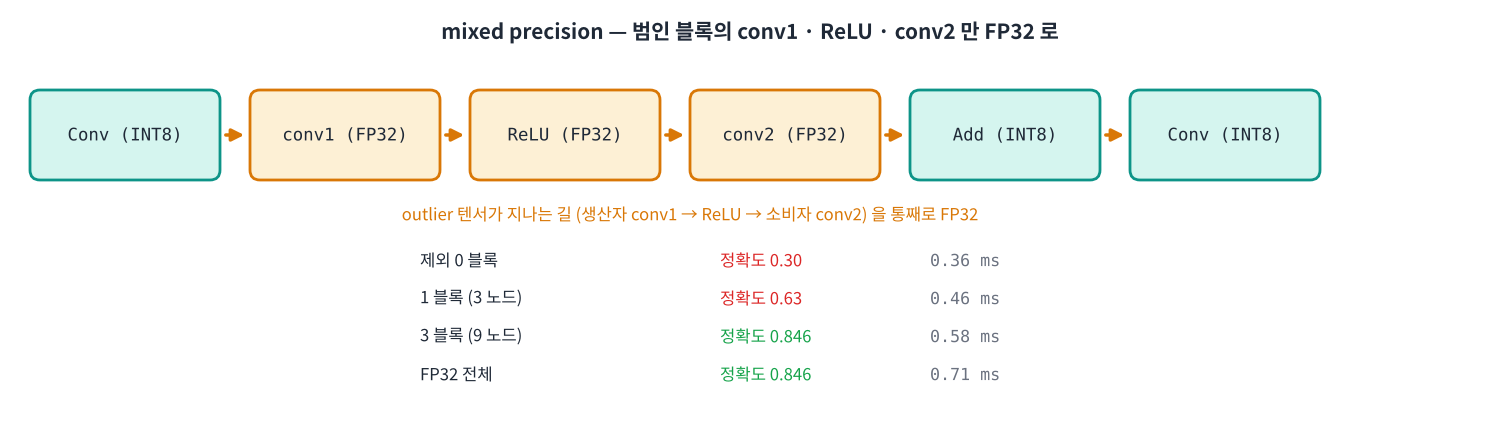

In [ ]:
#@title 🖼 그림 — mixed precision — 범인 블록의 conv1 · ReLU · conv2 만 FP32 로 남긴다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f3_mixed.png", embed=True, width=860))

**✍️ 직접 구현 3-1** 블록 이름(`"layer1.1"`)을 받아 그 블록의 **conv1 · 첫 ReLU · conv2** 노드 이름 3개를 `bad_pre.onnx` 그래프에서 찾아 돌려주는 `block_nodes(block)` 을 만드세요. (shortcut Conv 와 블록 끝의 `Relu_1` 은 빼야 합니다.)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-1 — 실행할 때마다 하나씩
show_hint("3-1", "67iU66GdIOqyveuhnCDsoJHrkZDsgqw6IGBwID0gZiIve2Jsb2NrLnNwbGl0KCcuJylbMF19L3tibG9ja30vImAg4oaSIGAvbGF5ZXIxL2xheWVyMS4xL2AuHuywvuydhCDsnbTrpoQg7IS4IOqwnDogYHAgKyAiY29udjEvQ29udiJgLCBgcCArICJSZWx1ImAsIGBwICsgImNvbnYyL0NvbnYiYC4e6re4656Y7ZSEIOyInOyEnOuMgOuhnDogYFtuLm5hbWUgZm9yIG4gaW4gZ3JhcGgubm9kZSBpZiBuLm5hbWUgaW4gd2FudF1gLg==")

In [ ]:
# ✍️ 직접 구현 3-1 — 블록의 conv1 · Relu · conv2 노드 이름
def block_nodes(block, graph=g_bad):
    # TODO
    pass

for b in suspects:
    print(b, block_nodes(b))

In [ ]:
assert all(len(block_nodes(b)) == 3 for b in suspects) and block_nodes("layer2.1")[1] == "/layer2/layer2.1/Relu"
assert not any("shortcut" in n or "Relu_1" in n for b in suspects for n in block_nodes(b))
print("✅ 범인 블록마다 conv1 · Relu · conv2 — 3개씩")

In [ ]:
#@title 🔒 정답 보기 3-1 — 강사가 알려 준 실습 3-1 잠금 코드를 입력하세요
show_answer("3-1", (
    "smfqFk8p0H7OQlr6PIkA+IonjyV9crsmKBRClD8wy3IpUuL1mROJ+6kO9ox20h6oZ4SCEKOICV6NdyZXGQrrMN8O"
    "4HN2t7ppJQ3a4MAPj6UvIla9mECKF+W9MAiZAtskvjIrjYK1e4pT9CNuv07gPDKZXyUdS6KmmGE5ZKp3QJaIzO5o"
    "THLHXNU0Sq+iKtoVl3sQfuQkKFgbRwqGNXardiJkLA0Daxk42CcWqHZHm3KcdyqRhj/lThlG3sjlFmXgWCkyw2yy"
    "aTB/SJ+58K74uUJX/Lh/hX74+XemhInokvKQLkjs5iu65IAi+4hnbLNXKDw3b8ACvASkA1y6ZP1iDyZpYZDr0mRP"
    "5b44MzggSkKolTiFVOqpP0nn3nV5U1i1U7KxBD2gFeZd9yxyxx+mhFpF75USO/RN0wy7xXtVk9RneSkia17fs+UN"
    "uQ68jiAWLD/cNw/hmVBLGhAcY45MnKxjPlMxNJrBUo8FRISUAAGny1epXQp73HjnEgAX6U2YbbZCLH1hQrGrFl3H"
    "PikjaEJLYtxFkp53EH44+7zKVw86jPVKt+Ql1Tb3UxKRGKjox3ymUCguFZWlpSypMr4YsE001MRWaWORU09VN69L"
    "dBMHpReLjwF+QmbS7ZImsnGYioLauTVTJeq02LB8H6kPVCFbpfU1gt2aHhUK81dAaj1B4RtxNYHh651DcaIe9dL5"
    "wLJcksQ7LgCPFlM0qI/Z5t8kq+V9GsDEU8ae3R+yOEHO3tI8/U76LyIdbQIX"
))


**✍️ 직접 구현 3-2** 단독 민감도가 **낮은 블록부터** 0개 · 1개 · 3개를 FP32 로 남긴 mixed precision 모델 `bad_mix{k}.onnx` 를 만들고, 정확도 · 배치 1 지연 시간 (스레드 1, `bench_fn`) · 크기를 `mix_df` (열 `n_blocks`, `n_nodes`, `acc`, `mean_ms`, `size_kb`) 로 정리하세요. FP32 지연 시간 `fp32_ms` 도 잽니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 3-2 — 실행할 때마다 하나씩
show_hint("3-2", "7Iic7IScOiBgc2Vuc19kZmAg7JeQ7IScIHN1c3BlY3RzIOunjCDqs6jrnbwgc3FuciDsmKTrpoTssKjsiJwg4oaSIOqwgOyepSDrgpjsgZwg67iU66Gd67aA7YSwLh5rIOqwnCDruJTroZ3snZgg64W465OcOiBgW24gZm9yIGIgaW4gb3JkZXJbOmtdIGZvciBuIGluIGJsb2NrX25vZGVzKGIpXWAg4oaSIGBwdHFfb3J0KC4uLiwgZXhjbHVkZT3qt7gg66qp66GdKWAuHuyngOyXsDogYHMgPSBtYWtlX3Nlc3Npb24ocGF0aClgIO2bhCBgYmVuY2hfZm4obGFtYmRhOiBzLnJ1bihOb25lLCB7ImlucHV0IjogeDF9KSwgbj0yMDAsIHdhcm09MjApWyJtZWFuIl1gLg==")

In [ ]:
# ✍️ 직접 구현 3-2 — 제외 블록 0 · 1 · 3개
x1 = X_ev[:1]
fp32_ms = None   # TODO: bad_pre.onnx 지연 시간
order = None     # TODO: 범인 블록, 가장 나쁜 것부터
rows = []
for k in [0, 1, 3]:
    pass         # TODO: bad_mix{k}.onnx 만들고 n_blocks · n_nodes · acc · mean_ms · size_kb
mix_df = pd.DataFrame(rows)
display(mix_df.round(4))
print(f"FP32 {fp32_ms:.3f} ms · 정확도 {ort_acc('bad_pre.onnx'):.4f}")

In [ ]:
assert list(mix_df.n_blocks) == [0, 1, 3] and list(mix_df.n_nodes) == [0, 3, 9]
assert mix_df.acc.is_monotonic_increasing and mix_df.acc.iloc[-1] >= ort_acc("bad_pre.onnx") - 0.01 and mix_df.acc.iloc[0] < 0.5
print(f"✅ 제외 0 → 1 → 3 블록: 정확도 {' → '.join(f'{a:.3f}' for a in mix_df.acc)}")

In [ ]:
#@title 🔒 정답 보기 3-2 — 강사가 알려 준 실습 3-2 잠금 코드를 입력하세요
show_answer("3-2", (
    "phRCzu6YnWNoH6pIh21g3OvvKirX9wB1Ie7B5INICr0S1HMcvDmqR3NeiXd7LWaHYoG9mmLn2PJSRikz5x1+GcAe"
    "a+FuHjlqXVqzgHDYkXCNKjI4KeJ+jmYkxXOWVDVfMHT2kbRQLT8fkRWZKudolWWDyzuWIfc9cRzJsnDZ6xZkvBBC"
    "C0tZ89SzGSaXIg4YOo4lvC9m4Kw0l/w3HssHGGUqXNOw6lHgWFqIrlvZp4ymQ4LJqJJC8Apwh6Kos8no0X0yYEA6"
    "nZmQL+6lcsowp1h6CuAy1j45nBs06VCtu3Xo5A6XOkyldgoqORn3LXLjgzBiO0v+m4feS+rIBTmbJr7l4ooBRzh4"
    "McMG4uqfpGoOrGgEcWVmkAbqEef/4f4We2dCpl3fpdYV40dd+FTqD2bJZDkHZZ8hAmR6k7DvN8p3CyUrdXmYC5Se"
    "bm0F6j7FrrxZ7J80kH4snFrGXzwzCNx2YOz1VOSs8oOOyR5+FGLfPu4Uo+92xVlbEqaO9yo6ij1vFM25oIPL4kHR"
    "+9ZuLpnTVNFpai/Sp/VjGgCVSf59XyMB775ZGsHZY426GaTxny5gAdiwACp2gnEpURLjWtLY2qAKoEOO8THu2pN+"
    "26ictqSU40fBx8F76eW/ypzyll5otI9ykW+VkvzX95P55FR4JmtkvaC5A1UinOoffKOAjyNhhHBLxtgkZXLtCVwT"
    "NCVldiTfs4f9LeDh9VMtbpLUmQ+aP8S6tPt9kX+kFtXsIPkynLs9nYrNQlwUhgpiGa1x1XQLARy9jt3T/OL6TOB0"
    "GPTrnz2iZPQSG1rjldEs7DrZlH359MPFOo0LWDpO8PY9Bd7N59nW7yNHqNzr7pq/A1xUHyS1qHtdunF8tC0TJcbs"
    "PpFNvHfirTzngH7TOC5TpRLwv3jcTqBYZ60s8psb8JXBapzbBNuWzoDHjOchNy4GRHqtFAk2mfEvR9cBZ/QzittF"
    "EM92q+66i4Yf3IfzPv44rJdtgkLIODrbXPG5kY2mPQBi0pzv+qiNCZFyjiHNcN1valDYygpplf1YfM2Y1L8tVvsu"
    "bhG9jsmOi9zs/vYwHjuO3N8YRrR1wrbH80pGP2teovkR/XoySzJ5cYOG/QFCbwGxLAgmjQskq7/mru7niIC6ebI9"
    "kcNEf71Q6DRKzxzFrQ0aExbJD7/UhtbgIo2r+AYMgjeOFi8d0qOiEzoDykcdePiZp3blMwN+fujz2gvdKrmKdUa9"
    "kMJMl+mRFZyU6YPyw1b7sJ+1km1kQiXkAiOQ/J5zaBdSsUa0VDFXJQFovh9H5QNDh1zkbvCJWdPQadDuysMLo+nx"
    "oQgK38QAGpA91o/2cV45AGSMlIZ4t9eWSgIrv7gsnflsyakNO8nKLYuT/hjl/kWLgkq1ogLAokBRK03GQRhn5qQQ"
    "xYkfOIGYbpDZFrUOs6SliN2ZYxFE7suyCkC+tayB838DkFCaMZi9Ofw6d51lPewWGtadfoTPkYi9iXUyvas8jWZe"
    "yQYclpUfMQRFdRpJ1UGp53A1m+q2isxPZMtyc9ugGAz7Vbrae2cNW4duUaAN0by8XA7t+3gv9Lz/Q0fjOwJsdwOq"
    "v5PUlIA+Ml3SX0EUaFihNeryu7EyFviuePM6ksrrnxuge/ABF4FvcjAV/Yb9UeIgfyE="
))


In [ ]:
# 🔁 바꿔보기 — conv2 만 빼면? (outlier 텐서는 conv1 의 출력이라 여전히 양자화된다)
only_c2 = [n for b in suspects for n in block_nodes(b) if n.endswith("conv2/Conv")]
print("conv2 만 FP32:", round(ort_acc(ptq_ort("bad_pre.onnx", "bad_c2.onnx", exclude=only_c2)), 4), "| conv1 · Relu · conv2:", round(mix_df.acc.iloc[-1], 4))

> **다른 처방 — 채널 균등화 (cross-layer equalization)**: BadQuantNet 은 '채널을 300배 키우고 다음 weight 를 1/300 로' 만든 모델이었습니다. 반대로 하면 (outlier 채널을 1/300 로, 다음 weight 를 300배로) FP32 함수를 바꾸지 않고 범위만 고르게 만들 수 있습니다. LLM 양자화의 **SmoothQuant** 가 이 아이디어입니다. 오늘은 '범인을 FP32 로 남기는' 방법을, Day 4 에서는 '학습으로 범위에 적응시키는' QAT 를 씁니다.

#### 📌 3교시 정리

- `nodes_to_exclude` 로 범인 노드만 FP32 → **mixed precision**. 범인 **텐서가 지나는 길 전체** (생산자 · 소비자) 를 빼야 한다.
- 제외 블록 0 · 1 · 3 → 정확도 0.30 · 0.63 · 0.85, 지연 시간은 조금씩 늘어난다 — 표로 보고 결정한다.

## 4교시 — TensorRT INT8 개념: implicit vs explicit (QDQ)

| | **implicit** 양자화 | **explicit** 양자화 (QDQ) |
|---|---|---|
| 입력 | FP32 ONNX + **calibrator** 클래스 (`IInt8EntropyCalibrator2`) | **QDQ ONNX** (scale 이 이미 들어 있음) |
| 범위를 정하는 곳 | TensorRT 빌드 중 | ONNX Runtime · ModelOpt 등 **바깥 도구** |
| 어느 layer 를 INT8 로 | TensorRT 가 알아서 (빠른 쪽으로) | **Q/DQ 가 있는 곳만** — 우리가 정한다 |
| mixed precision | 어렵다 | Q/DQ 를 빼면 끝 (3교시 그대로) |
| TensorRT 10 | **deprecated** (곧 사라짐) | **권장 경로** · QAT 모델 (Day 4) 도 같은 방식 |

TensorRT 의 INT8 은 **대칭 (zero_point = 0) · 부호 있는 INT8 (S8)** 만 받습니다. Day 2 의 x86 최적 설정 (활성값 **U8**, 비대칭) 으로 만든 모델은 TensorRT 에 그대로 넣을 수 없습니다 — Day 1 4교시의 '대칭 vs 비대칭' 이 여기서 다시 나옵니다.

**INT8 + FP16 fallback**: 빌드 플래그에 `INT8` 과 `FP16` 을 함께 켜면, Q/DQ 가 있는 layer 는 INT8, 없는 layer (mixed precision 으로 뺀 곳) 는 FP16 으로 실행됩니다. `trtexec --onnx=model_qdq.onnx --int8 --fp16` 과 같은 뜻입니다.

> 🎬 **애니메이션** [D3-4 TensorRT INT8 조건](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-4)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

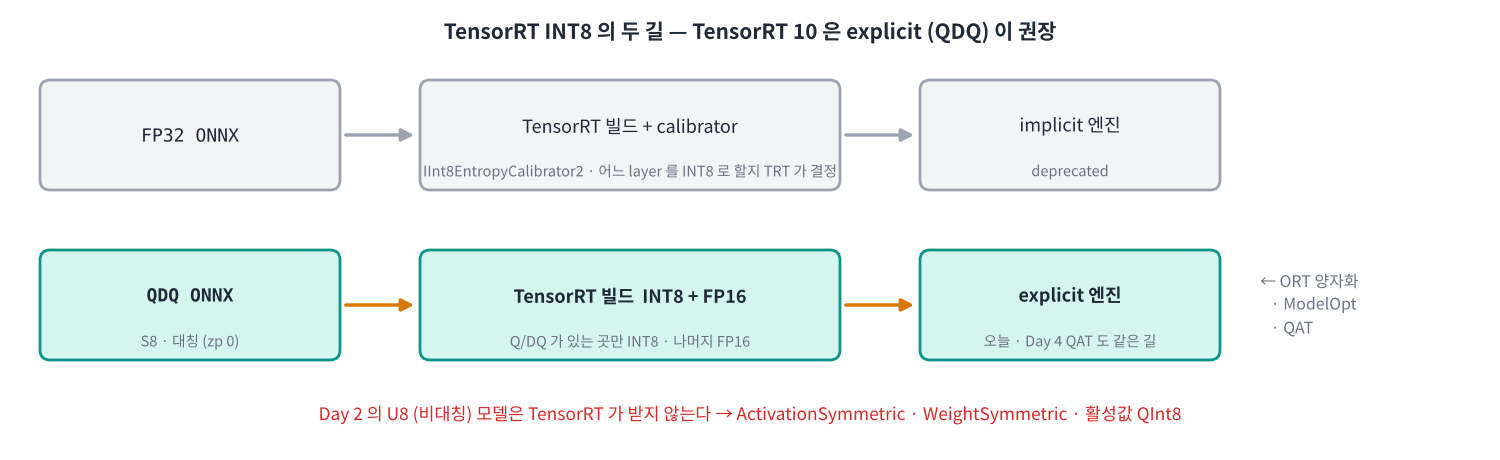

In [ ]:
#@title 🖼 그림 — TensorRT INT8 두 길 — 오늘은 QDQ ONNX 를 넣는 explicit 경로
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f4_trtq.png", embed=True, width=860))

**▶ 예제 4-A (제공 코드 — 실행만)** ONNX 파일을 받아 TensorRT 에 넣을 수 있는 QDQ 인지 점검하는 `trt_check(path)` 입니다. 모든 `QuantizeLinear` · `DequantizeLinear` 의 zero_point 를 확인해 `{"qdq": Q·DQ 노드 수, "uint8": zero_point 가 uint8 인 개수, "nonzero_zp": 0 이 아닌 zero_point 개수, "ok": 앞의 둘이 모두 0}` 을 돌려줍니다. 1-1 의 `rn20_int8.onnx` (Day 2 설정) 를 점검합니다 — 합격할까요?

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 4-A — 제공 코드 (그대로 실행)
def trt_check(path):
    g = onnx.load(path).graph
    init = {i.name: numpy_helper.to_array(i) for i in g.initializer}
    qdq = [n for n in g.node if n.op_type in ("QuantizeLinear", "DequantizeLinear")]
    zps = [init[n.input[2]] for n in qdq if len(n.input) > 2 and n.input[2] in init]
    r = {"qdq": len(qdq), "uint8": sum(z.dtype == np.uint8 for z in zps), "nonzero_zp": sum(bool(np.any(z != 0)) for z in zps)}
    r["ok"] = r["qdq"] > 0 and r["uint8"] == 0 and r["nonzero_zp"] == 0
    return r

print("rn20_int8.onnx (Day 2 설정):", trt_check("rn20_int8.onnx"))

In [ ]:
r_ = trt_check("rn20_int8.onnx")
assert r_["qdq"] > 100 and r_["uint8"] > 0 and r_["nonzero_zp"] > 0 and r_["ok"] is False and trt_check("rn20_pre.onnx")["ok"] is False
print("✅ Day 2 의 U8 모델은 TensorRT 조건 불합격 — 활성값 zero_point 가 uint8 · 0 이 아님")

> 💡 **예제 4-A 해설** — Q/DQ 노드의 입력은 (x, scale, zero_point) 순서라 input[2] 가 zero_point 입니다. Day 2 모델은 활성값이 U8 비대칭이라 zero_point 가 uint8 이고 0 이 아닙니다. TensorRT 파서는 이런 모델을 만나면 'zero point must be 0' 류의 오류로 빌드를 멈춥니다. 빌드 전에 점검하는 습관이 시간을 아낍니다.

**✍️ 직접 구현 4-1** TensorRT 용 INT8 ONNX 를 만드는 `make_trt_int8(src, dst, reader, exclude=())` 를 완성하세요. QDQ · per-channel · 활성값과 weight 모두 **S8** · `extra_options={"ActivationSymmetric": True, "WeightSymmetric": True, "QuantizeBias": False}`. 그리고 ResNet-20 을 **배치 1 고정**으로 `rn20_b1.onnx` 에 내보내 전처리 → `rn20_trt_int8.onnx` 를 만들고, `trt_check` 와 정확도 `acc_trt_int8` 를 확인합니다 (배치 1 이므로 reader 도 `bs=1`).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 4-1 — 실행할 때마다 하나씩
show_hint("4-1", "YHF1YW50aXplX3N0YXRpYyhzcmMsIGRzdCwgcmVhZGVyLCBxdWFudF9mb3JtYXQ9UXVhbnRGb3JtYXQuUURRLCBwZXJfY2hhbm5lbD1UcnVlLCBhY3RpdmF0aW9uX3R5cGU9UXVhbnRUeXBlLlFJbnQ4LCB3ZWlnaHRfdHlwZT1RdWFudFR5cGUuUUludDgsIG5vZGVzX3RvX2V4Y2x1ZGU9bGlzdChleGNsdWRlKSwgZXh0cmFfb3B0aW9ucz17Li4ufSlgHmV4dHJhX29wdGlvbnMgPSBgeyJBY3RpdmF0aW9uU3ltbWV0cmljIjogVHJ1ZSwgIldlaWdodFN5bW1ldHJpYyI6IFRydWUsICJRdWFudGl6ZUJpYXMiOiBGYWxzZX1gLh7rsLDsuZggMSDqs6DsoJU6IGBleHBvcnRfb25ueChybjIwLCAicm4yMF9iMS5vbm54IiwgYmF0Y2g9MSlgIOKGkiBgcXVhbnRfcHJlX3Byb2Nlc3NgIOKGkiBgbWFrZV90cnRfaW50OCguLi4sIENpZmFyUmVhZGVyKFhfY2FsLCBicz0xKSlgLh7soJXtmZXrj4Q6IGBvcnRfYWNjKCJybjIwX3RydF9pbnQ4Lm9ubngiLCBicz0xKWAgKOyeheugpeydtCDrsLDsuZggMSDqs6DsoJXsnbTrnbwg7ZWcIOyepeyUqSku")

In [ ]:
# ✍️ 직접 구현 4-1 — TensorRT 용 INT8 ONNX
def make_trt_int8(src, dst, reader, exclude=()):
    # TODO
    pass

# TODO: rn20_b1.onnx → rn20_b1_pre.onnx → rn20_trt_int8.onnx
acc_trt_int8 = None   # TODO
print(trt_check("rn20_trt_int8.onnx"), f"| ORT 정확도 {acc_trt_int8:.4f}")

In [ ]:
assert trt_check("rn20_trt_int8.onnx")["ok"] and onnx.load("rn20_b1.onnx").graph.input[0].type.tensor_type.shape.dim[0].dim_value == 1
assert acc_trt_int8 > cmp_df.fp32[0] - 0.01
print(f"✅ TensorRT 조건 합격 · 정확도 {acc_trt_int8:.4f} (FP32 0.846)")

In [ ]:
#@title 🔒 정답 보기 4-1 — 강사가 알려 준 실습 4-1 잠금 코드를 입력하세요
show_answer("4-1", (
    "CrwyOEJx6wCG1bXzjtAswZppovrIZHucpjWlJ2Xl2ifKPAbNPz/7BbXGT2IoxBWj+DPsRQZkQ2k9lpzXtzByF1pt"
    "1ZJAjfjHHUIOqBqjiEnYHMOB6NwhE9EVGx78HO2L6Ah/VoLDqunM1U34CfVRaIjIm1UUQ1MuOEF+URJUiRnvbNPp"
    "plaEy05sWuhjWa5gMds6WoLmwsfSSZhSNMOnVV6tkgOy1ibrOT+DSCTYFkuvKvRwpxMs9/wPjzvTsw3OcOIyjUes"
    "jcYaImrchwEqfJ28imUCMKsydnzvs7P7kottAEjiLyflV9B8ZK6IxFgdvjYclWzmtDcWHQ0ZhkFoMJUDKB/SYA1Q"
    "8Zon98RCAcbBI7oAfNYYESqyVTYI62HIYZRpdz+Aor+yUG28k2/guqL1hgX31jdhs5VVhr8PEFsh55wmz7NYilDg"
    "AaoxUgSXhWqqEsSAQrGgvTFSHVwIUjq41OJPW7MDD59NQzdsxknbMk5HDGZpC/0lMyLj1K1js85uX6D72yY+bUE1"
    "GRAvT1B1SQyfe6OCuxdK9GZLkUb6rxTY0sd1kcFePQWzpwe73dRgF1Z+9MglyPnoM0wbYgVcEWS9d+WMISEELVr/"
    "6t8LuqVUp1yLM2j7NvxrOVrNjLdE2uiM3pTx0K962FsUboAFeRNF2LfuDygWdP1hzCjztdzu3IOpoxpiVBD7cqP7"
    "65ne270aYZH1enoRh2XGBz1UDBRbbA6WuKnmyMO6OFLbiRK5CNSdkAgSSw0OOCeL9Cr10bLHL0Yv0ar4r0pM+5+M"
    "nPbvt5/mFjtB7lF1ctOlZ4iO3MzTXmiP+ec9SoB1Oc7eRUX3r2u83KfQjjhbJHwsjUIfAKar99WG3VyzyxMF3YGr"
    "0wK5d8KEgO/AEBQv8lV/DtTdKiPXtCymrK3tg9XBUsrRZgxJtBHIP0WbLbbGXNt7hByrQUzYixX2WbJPnDuyHA0V"
    "eNQsUhXsRgUhx/MZsTiw3YKP5srEcqEHmaamk89ANxLb2eEseMGW1jufxs5iIulFSNgWWar1Z6zyEiknoJOZz5VL"
    "pllMDaGIe+mesg6PVUZIJPlY7pC9awB+ne2TDZ01tXfC3xhaT7HIBemZj3z404Y5N4F3B7LvCLnK0UravmAXUQFH"
    "IIOOrhb215MiRJ7Kzjhj/CBSGENfpaS1//XHDCWRrOTYC0Fcqgi+FWhMnuc88CH4khqlaRjQU4I6jZTV6JaFNWeW"
    "rgZ0/1vbbEHeitSwMs9KlGUPsVCIkZexsTUXhAS/9nLHJ5/M2eB8GVrrcM7wFflsspV/vFfTOmdPDcoMDLfNNy02"
    "IZzlImgEuPxYgg/AdBAcC1hZ02UljAsrL25Td3/CX8DQ+GrZm7kcbEBbiWkesWOasFcPE3X64s9jUU7B3iYPeK5s"
    "ZZudjJ310lUA10eROhQ7/hJ3ZB48SpqcWhE8M7iL44LueBY5AVfJ/aqtqcA2pMCvl18fSdOrgSN9X4r8LXSzhsvn"
    "nQMGGKtZzNMAu3seqhvEp5mm7JXXVRcfL7HQmj/OmNgU632ZC1pa0/cuS2wiY6L0MaH83U1gHtc0PcQvSQ74P9JH"
    "WD4+awfbvqYT7yjvu2ek7MFtfsKZ/kmQ7sSMLCz+zUibbzoZlZVsYglCMPJrh9/F+MfarY2Nng=="
))


**✍️ 직접 구현 4-2** OT Day 4 의 `build_engine` 에 **INT8 을 켜는 한 줄**을 더해 `build_engine(onnx_path, engine_path, fp16=False, int8=False)` 를 완성하세요. (GPU 가 없으면 정의만 하고 넘어갑니다. GPU 이면 `rn20_int8.engine` 을 빌드합니다.)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 4-2 — 실행할 때마다 하나씩
show_hint("4-2", "T1QgRGF5IDQg7J2YIGBidWlsZF9lbmdpbmVgIOydhCDqt7jrjIDroZwg7JOw6rOgIGBpbnQ4PUZhbHNlYCDsnbjsnpDrpbwg642U7ZWp64uI64ukLh5gaWYgaW50ODogY29uZmlnLnNldF9mbGFnKHRydC5CdWlsZGVyRmxhZy5JTlQ4KWAg4oCUIEZQMTYg7ZSM656Y6re4IOuwlOuhnCDslYTrnpguHkdQVSDsnbwg65WM66eMIGBidWlsZF9vbmNlKCJybjIwX3RydF9pbnQ4Lm9ubngiLCAicm4yMF9pbnQ4LmVuZ2luZSIsIGZwMTY9VHJ1ZSwgaW50OD1UcnVlKWAu")

In [ ]:
# ✍️ 직접 구현 4-2 — INT8 을 켤 수 있는 build_engine
def build_engine(onnx_path, engine_path, fp16=False, int8=False):
    builder = trt.Builder(LOGGER)
    network = builder.create_network(0)
    parser = trt.OnnxParser(network, LOGGER)
    if not parser.parse_from_file(onnx_path):
        raise RuntimeError("\n".join(str(parser.get_error(i)) for i in range(parser.num_errors)))
    config = builder.create_builder_config()
    config.set_memory_pool_limit(trt.MemoryPoolType.WORKSPACE, 1 << 30)
    config.profiling_verbosity = trt.ProfilingVerbosity.DETAILED
    if fp16:
        config.set_flag(trt.BuilderFlag.FP16)
    # TODO: int8 이면 INT8 플래그 켜기
    blob = builder.build_serialized_network(network, config)
    if blob is None:
        raise RuntimeError("빌드 실패 — 위 로그를 확인하세요")
    with open(engine_path, "wb") as f:
        f.write(blob)
    return engine_path

# TODO: GPU 이면 rn20_int8.engine 빌드

In [ ]:
assert {"fp16", "int8"} <= set(inspect.signature(build_engine).parameters) and "INT8" in inspect.getsource(build_engine)
if TRT_OK:
    assert os.path.getsize("rn20_int8.engine") > 0
print("✅ build_engine(…, fp16, int8) 완성" + (" · rn20_int8.engine 빌드" if TRT_OK else " (GPU 없음 — 빌드 생략)"))

In [ ]:
#@title 🔒 정답 보기 4-2 — 강사가 알려 준 실습 4-2 잠금 코드를 입력하세요
show_answer("4-2", (
    "baMd7MwsH6cKh/PQ2LOTtv9lxXWhWzBZl/sW/8KmgbjPBK7vkzbMHrpKTuq8MgN+HtCo7QEGprEZ/uoMrQ/hTuus"
    "m6kGTJaI62cJ0rqnWC+gPjbKwTAWSJ5SOgi31caLELa2D9LMbrJn2SBnY6kkrsoOmwl2NFV437eN30WN3/OJpBPE"
    "6XQLSylgMGXIxTCxxA9gV9XydVkcvgI031mV0GY+rCIF333AnUpnvS3OWIWCr/9NAWOZDHINedlDqTk6KXmuTPfS"
    "mBdKguFXO1MzigoKafOa4TMtJyR+6OEOaiuG4qjp/LmcknvqtBepNcnEHbhxhSsfftS4OklPK0LXcE19e6tqoSJW"
    "x7oU5waH1Rv2FUebKJBlmF9N9XfiVvt3SfdILAJP476JoOOc7OkWzYPhFWWUIU5Jno18JDfdcTGGHB/NnV76Z2mk"
    "5Gos1bbrQ+KZh5THXlSEyMDPmi3wL1Mjms4E8RVtvs/4If1+KCpTVBMJVOVRG4S3yYhEPuaOGOASf1oRB8RCVAaO"
    "KOiKxezmE7rVBaQsid7tI2dLorya0b9sP1WFf2beW8F+sf4bBQaDTwkBxlhhC7yHWKCpjZPN7dQXfkBDR5RwIIrv"
    "ikWVanTgNDPm9gkPujMlWDXuLH12qxLCKmcm5rmi2Eo0ORvjopZU5twzCLZNCbz6s59v6R3eeCx2aiykxe0HB9vW"
    "/17Dot7goaFUAGl0YvPMP7HzOvT+b3r5eJUn2AFMrjpSW0/ai3wwmN5CTFiB5CCe/y7MNA75YYFbCUG6Z9B6LFEl"
    "3a9CcntOmngS7QnU1yPdi32w4yzItUeFAR22JZeSXrHm7PI6QWl2RzrLDKRL6uoiFQNtc7hDmA+8TrT7r6xYmMz6"
    "arPezWcOfVk8k2pCowgjF/qO/hwmtM5V0aSklekiw2xA6ZVfXaHJ1AxyPy9u6PpBv6rFIv5VW2yI6Kcj1e4RKQHm"
    "9jjOYSUmvR+paJOfGmNejnvtq0iP8upEBj+1sr2SiRVGXE2CBdbxHcfxxp0B50bTM84PnytMR1rq0j90jehOqrbR"
    "Cl/KQymSiEynEzBg9TQKmgj6pz09/TY2Dnq/HQHU1R5nfNG0l422wxKkLfXRFLrXRoNtfQmCOOimDY7/4p4+fKWC"
    "OJvk57pJl3F58i2l4zhpZVJPy/6apVSXsH4Fgml2y8Kp8H/kxx6TaIcG6870UcZ+IDnkzguU26dPHSXc+Bx3jI0+"
    "B/CzZNDmBr5XXYiJxxNzmJhNMIfyDCJoBiVD6O8fxd8QU2+PlLq/dD+lW1s4iyxRq+xK0l+Dq/DLawTtelxjXos7"
    "my9C5xKSJVGopqGcM8xeLo9TRuwwdb6v4+x+IL8+moNsdolqhcg0HidLlLa6B9qKwnlH+gZs8HJe26DrxSBsi/ef"
    "O7nYzYPrpYZe0smlGUEDs2d+2jYBPC36gnUTZC79A7VriqXXfzNW9GEBYyFf94SJvg3mKaboFr2kekPnSUZvnpJW"
    "gf2hHdFNVox/DG1TCPGCbU3b/H73aVVokIgCMQVzdk/dfMdvbKE/1nPcSfe+JLOPEcDM4EpSTy3l9iXHkhsedfYM"
    "c8htcem/nNABGoEOTUItmcC4V8Lir6818w0ce3MLrmHTsq56Rw0PJfvIKMEq1GjfmkhL01RN2Koh520T8botKcgf"
    "jpNx13cfy+0dZXLWSqNpNxyl36G3dn22P5LixWoDkgCed8dpV8no6k7myOjolA0/VtKNz37p4ubjzMvHbklJXKa3"
    "wQkg2vcFjGLS//bnJXvgCx44ZPoKrOTE5v/6/J4gRK7+KqnascvKVYYMNcQuCXDAMJ+wsj+P5lwTPWt1t0Oh2Xq9"
    "tesVTfXeUrK5CVv5xbHcwFdfl3UkrXAS83uTX8CbdeWXm7F++fgu6WO94DKaGBXT54dYh52+HSidWFbGcc6UGTEy"
    "iV2w7Y0sI8/Ljfdoly8Q7P13KJCCcFCP0PDCA6b4hyBXTycq5IFr7GntxlPTmwIzbABgezV8RnHmAHtdohYl+soG"
    "xjvyZO1y0jPWai1382Dpj+Up2zdgLRkc0rbWRx5btZP5c6pT1A5v+eSa6oQZdPE3H7/6dUeLu/ggBVV3G30FPU49"
    "eNeNDNHYa+x9Ne0YdB3Nd9dLuAs3RktscQ6DyaryxeDq8Wj/p4hT8Eb/uSasyA=="
))


#### 📌 4교시 정리

- TensorRT 10 의 INT8 은 **explicit (QDQ ONNX)** 이 권장 경로. implicit calibrator 는 deprecated.
- TensorRT 는 **S8 · 대칭 (zero_point 0)** 만 받는다 → `ActivationSymmetric` · `WeightSymmetric` · 활성값 `QInt8`.
- 빌드는 OT 코드에 `BuilderFlag.INT8` 한 줄. `FP16` 을 함께 켜면 양자화하지 않은 layer 는 FP16.

## 5교시 — INT8 엔진 빌드: FP32 · FP16 · INT8 비교

같은 ResNet-20 으로 엔진 세 개를 만들어 **정확도 · 지연 시간 · 엔진 크기**를 비교합니다.

| 엔진 | ONNX | 빌드 플래그 |
|---|---|---|
| FP32 | `rn20_b1_pre.onnx` | (없음) |
| FP16 | `rn20_b1_pre.onnx` | `FP16` |
| INT8 | `rn20_trt_int8.onnx` (QDQ) | `INT8` + `FP16` |

> ⏱ 시간은 **T4 · 세션마다** 다릅니다. ResNet-20 은 아주 작은 모델이라 배치 1 에서는 데이터 복사 · 실행 준비 시간이 대부분이어서 INT8 의 이득이 작게 보일 수 있습니다 — 8교시의 YOLOv8n 에서 차이가 더 잘 보입니다.

> 🎬 **애니메이션** [D3-5 엔진 세 개 비교](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-5)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

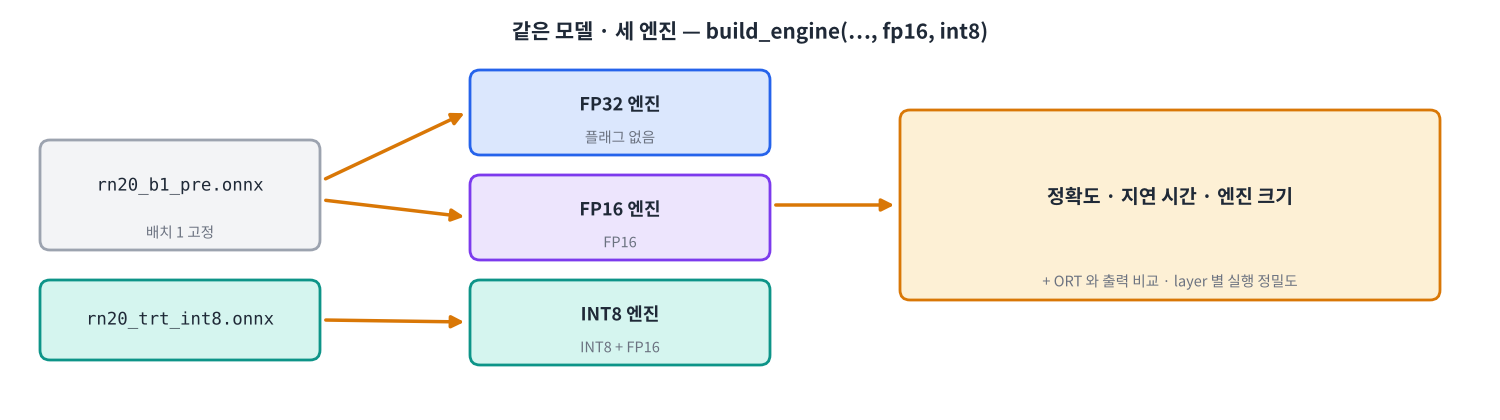

In [ ]:
#@title 🖼 그림 — 같은 모델 · 세 엔진 — 정확도 · 지연 시간 · 크기를 한 표에
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f5_engine.png", embed=True, width=860))

**✍️ 직접 구현 5-1** 위 표의 엔진 세 개를 만들어 (`build_once`), 평가용 2,000장 정확도 (배치 1), 지연 시간 (`bench_fn`, 배치 1), 파일 크기 (MB) 를 `eng_df` (열 `precision`, `backend`, `acc`, `mean_ms`, `size_mb`) 로 정리하세요. **GPU 가 없으면** FP32 · INT8 은 ONNX Runtime CPU 로 같은 값을 재고, FP16 행은 `NaN` 으로 둡니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 5-1 — 실행할 때마다 하나씩
show_hint("5-1", "7KCV7ZmV64+EOiBgaW5mZXIoWFtpOmkgKyAxXSkuYXJnbWF4KCkgPT0geVtpXWAg7J2YIO2Pieq3oCAo67Cw7LmYIDEsIDIsMDAw67KIKS4eR1BVOiBgVFJUSW5mZXIoYnVpbGRfb25jZShzcmMsIGYicm4yMF97cHJlYy5sb3dlcigpfS5lbmdpbmUiLCBmcDE2PWYxNiwgaW50OD1pOCkpYC4eQ1BVOiBgcyA9IG1ha2Vfc2Vzc2lvbihzcmMpOyBpbmZlciA9IGxhbWJkYSB4LCBzPXM6IHMucnVuKE5vbmUsIHsiaW5wdXQiOiB4fSlbMF1gIChGUDE2IOydgCBOYU4g7ZaJKS4e7KeA7JewOiBgYmVuY2hfZm4obGFtYmRhOiBpbmZlcihYX2V2WzoxXSksIG49MzAwLCB3YXJtPTMwKVsibWVhbiJdYCwg7YGs6riwOiBgc2l6ZV9rYijtjIzsnbwpIC8gMTAyNGAuIOy2lOuhoOq4sOuKlCBgSU5GRVI1W3ByZWNdYCDsl5Ag7KCA7J6lLg==")

In [ ]:
# ✍️ 직접 구현 5-1 — 엔진 세 개 비교
def run_acc(infer, X=X_ev, y=y_ev):
    # TODO
    pass

ENG = [("FP32", "rn20_b1_pre.onnx", False, False), ("FP16", "rn20_b1_pre.onnx", True, False), ("INT8", "rn20_trt_int8.onnx", True, True)]
rows, INFER5 = [], {}
# TODO: ENG 를 돌며 추론기 만들기 → acc · mean_ms · size_mb
eng_df = pd.DataFrame(rows)
display(eng_df.round(4))

In [ ]:
assert list(eng_df.precision) == ["FP32", "FP16", "INT8"] and {"backend", "acc", "mean_ms", "size_mb"} <= set(eng_df.columns)
e_ = eng_df.set_index("precision")
assert abs(e_.loc["INT8", "acc"] - e_.loc["FP32", "acc"]) < 0.015 and e_.loc["INT8", "size_mb"] < e_.loc["FP32", "size_mb"]
print(f"✅ {BACKEND}: INT8 정확도 {e_.loc['INT8', 'acc']:.4f} (FP32 {e_.loc['FP32', 'acc']:.4f}) · 크기 {e_.loc['FP32', 'size_mb']:.2f} → {e_.loc['INT8', 'size_mb']:.2f} MB")

In [ ]:
#@title 🔒 정답 보기 5-1 — 강사가 알려 준 실습 5-1 잠금 코드를 입력하세요
show_answer("5-1", (
    "JqPHAqHejqP5JyGSRE/fxAMzUngZZkUwSZ5lx87Ky/KbGSkgdjbSccL2CgKJ0My8i4BFbFJisg0spweN42yVcfuD"
    "wwL6QcqOfLAFdo0X7YHb7mRRpmmpI1rtNG07l0XI335n+cCI/tPcx0PJLrAAcKN6etQARwIDtYdeLC8petI6y5dJ"
    "oplzF1JXubIlObYefjz1oDXuz/ISlsm//LXMASuSv6ImGVZf8uVnm109O5i5vDJsXPAqYeXgtQ8Nvgo7Inq8CsBF"
    "GgUkTvkfgj7h+SKCaZXNOO6Ml8A//m8RMQ0hhOg9tCZv1I8CJws/kdPARjaD8U08Em5WeMFNYLBDi5Csl58txfX1"
    "aWVgJNKU97UbXYelBWX8xeEBxol9OwsyuGKxZ/6qP/QD36GkYWJMzG1fbnV856exeUwG0LatMrZe/WSfD+Qkis+e"
    "KF096KZ0L/kD/O31g90N/PtvCN0V6k1SBmTjo6HrteyrfnQAjukHyAnsY/OcLM9mp2j8pB2Rx902PYHDtkkMHtGh"
    "xlkTju9imHL9kY++IXPMXerJmYx8DwXX2NKs5y6VI8rKEvxkc3IXZE94+MgeyTHpbG9NTpryAv8D2kbYcpRgJjNl"
    "YZOMj2ny928VDWjfAcqeTyyLDpJFMzFC4deimbAEMNDE6a4GfGqk/nuLI1EUg3/n3T+yakU0VUlJodyGCRxPV7Uy"
    "bzLXCL/g84qRBWtUt8nYgHbPBSLiSy2fP3YHYsktqUB823CfZKXdEU9r9koSxPdQP0fKRqZS7Ugvz0TDWvF88ylc"
    "TIPw6L17yD2YJ1L1C9i0ZVMyZis5xp7REBAOzyvh8LOlDptQB0q5HY+5qtW1DaaqY1lzlYGsoVKA/uBknPP8UQzm"
    "Gil1hoKAEmLOjI50RtgVVHRI+ouQRWx97xSNT8IUAO5VTxjsSMkkpBFUJD7TkbOmxHsFCC3AU9Be5qSL8vXxcJiX"
    "8d1yRstKCdQbynF/vagEHyBed/h/lxMmLmeSEdpexP0+1bFGmzQs/6Ba6EX5KbtIE9ERXbsyZCVUDozdSk12cTUt"
    "AkDp0D3zSsTx4EPATyphJ842bNVKMCzJAIw2XuwnmBdd9GooUCvnUSoXaVCcVw2hkhSbAmprCQvnBQ4fQ7EJ8DDY"
    "AwzywHwJrtneUfUANNd4cZ9hxuD5S2sVG82H4GJXiO2sN1EiphwH4zGERemjBJ1I4RIerqy1isE9u8mr0syvSmVm"
    "8QDCI2NPouFTxyZr6Kz6ySNDsEM+bOznXWpCC1XUfHoss/i8W9W5Rjvgoz8ZOpbDntQ0Gaa43g1WzQBasJjMjKVK"
    "Qo73owGnx1CvgDCfNVX3hZWw4xPv15a35NXj/UoIjh8mdFUSlsWV7FstSDv5gEOggC9m7WJzyJ+NLj0qOf+2uutE"
    "+jHpG9+fTESNrM6Dhr3371vFGdjG7nBvJ36qNRBhsqw5nQDUx7bR5K4uboBfNRgrWLd58eC13MrfAE1oHUmb6l5Q"
    "uZRjynDlBJLmdrGw+HaRPO1b5v0ZiAw7l99r8Q19k6GZV1wlvankVsJPQ36EOSffOWDFqmDam5oHG3Bh3sKBIdf+"
    "6UBQ/T5owBH+6Wt9GGwa8BhYaG2/ZLiFht0c2m3C84/pzcaffyIrOGmoztb5nrDyb5jZRxPhju1Al8trR5XHebuD"
    "1CRdw5aiUDjz0n2VLklUeMx5SQd0/wT4foM0yTKguvjtafzTCqttsIMWwjNTHSINpawco7PsaquAMWzHw+25zqah"
    "5UGuXNUFk997+JnRPT/IyqzN51v1ag0Yt6uqjmrKRNece+BEjoBUuKyGGdEf5n/CWWTJDj7jpdnRyHUrC0cfSa2k"
    "ycMCdZL82X+U3YtjR88RP9iEQuVzBkx+/c/7rLM="
))


**Polygraphy** 는 같은 입력을 여러 런타임에 넣어 출력을 비교하는 NVIDIA 도구입니다. 명령줄로는 아래처럼 씁니다 (참고 — 오늘은 같은 일을 Python 으로 직접 합니다).

```bash
polygraphy run rn20_trt_int8.onnx --onnxrt --trt --int8 --fp16 --atol 0.1 --rtol 0.1
```

비교에는 **허용 오차 (tolerance)** 가 필요합니다. INT8 끼리라도 런타임마다 연산 순서 · 융합 · FP16 fallback 이 달라 숫자가 똑같지는 않기 때문입니다. 그래서 '최대 차이' 와 함께 **'예측이 같은 비율'** 을 봅니다.

**✍️ 직접 구현 5-2** 평가용 처음 300장에 대해 **ONNX Runtime INT8** (`rn20_trt_int8.onnx`, CPU) 과 **5-1 의 INT8 추론기** (`INFER5["INT8"]`) 의 logits 를 비교해, 최대 절대 차이 `max_abs` 와 argmax 일치율 `agree` 를 구하세요. GPU 가 없으면 두 쪽이 같은 ORT 라 차이가 0 입니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 5-2 — 실행할 때마다 하나씩
show_hint("5-2", "T1JUIOyqvTogYHNfcmVmID0gbWFrZV9zZXNzaW9uKCJybjIwX3RydF9pbnQ4Lm9ubngiKWAg66GcIDMwMOyepeydhCDtlZwg7J6l7JSpIOyLpO2Wie2VtCBgbnAuY29uY2F0ZW5hdGVgLh7ruYTqtZAg7Kq9OiBgSU5GRVI1WyJJTlQ4Il0oWF9ldltpOmkgKyAxXSlgIOulvCAzMDDrsoguHmBtYXhfYWJzID0gbnAuYWJzKGEgLSBiKS5tYXgoKWAsIGBhZ3JlZSA9IChhLmFyZ21heCgxKSA9PSBiLmFyZ21heCgxKSkubWVhbigpYC4=")

In [ ]:
# ✍️ 직접 구현 5-2 — ORT INT8 vs 엔진 INT8 출력 비교
ref_l, trt_l = None, None     # TODO: 각각 (300, 10)
max_abs, agree = None, None   # TODO
print(f"{BACKEND} INT8 vs ORT INT8 — 최대 차이 {max_abs:.4f} · 예측 일치 {agree:.3f} · logits 크기 {np.abs(ref_l).max():.1f}")

In [ ]:
assert ref_l.shape == trt_l.shape == (300, 10) and agree >= 0.95 and (max_abs < 1e-6 if not TRT_OK else max_abs < 5)
print(f"✅ 예측 일치 {agree:.1%}" + ("" if TRT_OK else " (GPU 없음 — 같은 ORT 끼리 비교)"))

In [ ]:
#@title 🔒 정답 보기 5-2 — 강사가 알려 준 실습 5-2 잠금 코드를 입력하세요
show_answer("5-2", (
    "vps1KT+7Sn9U83PhxlGYC4mkW9eqGDuH12zpjeyrX2oH3LHR5sGczZHIL5Iv9E2taoLHku9XofYB4lGQfqDvSSSq"
    "69OpJA5Pe/jReq+tVB+lEPXya1jVCeSaEK6X5mRl4gX5T4vaIpLAdsYb08JRHdcd1pPs41wgYwm7pHz9xS4oJoK/"
    "2IlqPkZw0raP/ca1DgbrpLHhBn0m5D8ZmMi0OQatgSJQYwfevd+RmQgBZJMQSCz1fEuaAzOA7SnLj1dNbrFCvLpR"
    "74+zsHYjCUmyXhMY25CXEaKFFv8bCZYi7FQx8wXswPG9ZXy/wn9qVMuIx50PbwGkGxWNkRBEpXQ2IIWEoRmugnMR"
    "YiEmp1MpOYN4GSINVLgiKqF3SXGdbmX+4mG3Ji13C7zVm3rFbypr+/8/7R3y1iHQgFblHMn8CjIqu2OvNWFnhacU"
    "pehSZ348ig0zC/TrfdUy6pMWrs6pOOM/DPdvXsHJ4ENu7hNngnnAWlY4H14CVvwjotXd8dR4lEBpLILni+OGx8E0"
    "6kypzeb8bhE8QvW6YUeuSdgrfhV34cRdiANj367v8VjIyWtliQ5yYFreIIzYkOIyukJHOAtm3M4oyIS2hvXrel88"
    "9p61gHQo1QiTKNe1PHQkp1wLfGRovqfhvXq3/SiGGCLhBSuqsk3cz0RzfYHOLwF6CCR/hq/qHoIttqVnBpkVBl4V"
    "PXYkVis1yExv+wtMfKG1foB1dAQA00qxnoDkh8tpEdkkOPYU5egkUiy0qFnGAKqZREP7YIz+TGmvH5VyxuSKDq5s"
    "lzqx/IVrSjcH8TJRVAHuuW8xAf+8FYSCvD43MYRKk+41znHF+q3ZLm7mYXzNNwNxOt5hB0HShNo5fuvdp3C5RFfZ"
    "LWevHG0Q1lvvD28YDGraZVRmevy/jO8LldN7i/7Mrn3ZTuRxwsjd0OTANGEAe9ZgsoRPdwxnKV0RnOFvWj74xe+T"
    "+VevPwHve4K7EQShELrQ6K7UaSofkSRr/8GUHeAaWhC6FfoBxXW0iLmVuVnYtDmez2VBNqVAWfe+OS01pByKNPo9"
    "Voxbt391eeiEty/B46fuAuvzf+TtrTO5fLqrp00VbnZWmcKZdIgXdcVekWfi2jbQYWoRdlqFGjDTUb5TKlFUo/zH"
    "hacBPYB23G07dcyKbw=="
))


**▶ 예제 5-A (제공 코드 — 실행만)** 엔진 안의 각 layer 가 **어떤 정밀도로 실행되는지** 세는 `layer_precisions(engine_path)` 입니다 (GPU 가 없으면 건너뜁니다). `engine.create_engine_inspector().get_engine_information(trt.LayerInformationFormat.JSON)` 의 `"Layers"` 목록에서 layer 마다 출력 정보를 문자열로 보고 `int8` → `"INT8"`, `half`/`fp16` → `"FP16"`, `float`/`fp32` → `"FP32"` 로 분류해 `Counter` 를 돌려줍니다. FP16 · INT8 엔진을 비교해 `prec_fp16`, `prec_int8` 을 구하세요. (GPU 가 없으면 건너뜁니다.)

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 5-A — 제공 코드 (그대로 실행)
def layer_precisions(engine_path):
    eng = RUNTIME.deserialize_cuda_engine(open(engine_path, "rb").read())
    info = json.loads(eng.create_engine_inspector().get_engine_information(trt.LayerInformationFormat.JSON))
    cnt = Counter()
    for L in info["Layers"]:
        s = json.dumps(L.get("Outputs", L) if isinstance(L, dict) else L).lower()
        cnt["INT8" if "int8" in s else "FP16" if ("half" in s or "fp16" in s) else "FP32" if ("float" in s or "fp32" in s) else "기타"] += 1
    return cnt

if TRT_OK:
    prec_fp16, prec_int8 = layer_precisions("rn20_fp16.engine"), layer_precisions("rn20_int8.engine")
    print("FP16 엔진:", dict(prec_fp16), "| INT8 엔진:", dict(prec_int8))
else:
    prec_fp16 = prec_int8 = None
    print("GPU 없음 — 건너뜀")

In [ ]:
if TRT_OK:
    assert prec_int8.get("INT8", 0) > 0 and prec_fp16.get("INT8", 0) == 0 and sum(prec_int8.values()) <= sum(prec_fp16.values()) + 30
print("✅ layer_precisions 완성" + (f" — INT8 엔진의 INT8 layer {prec_int8['INT8']}개" if TRT_OK else " (GPU 없음 — 건너뜀)"))

> 💡 **예제 5-A 해설** — ProfilingVerbosity.DETAILED 로 빌드해야 layer 별 정보가 자세히 나옵니다 (실습 4-2). 출력 정보에는 'Int8 NC/32HW32', 'Half ...' 같은 자료형 · 메모리 배치가 적혀 있습니다. TensorRT 는 Conv + BN + ReLU (+ Add) 를 한 layer 로 융합하므로 layer 수가 ONNX 노드 수보다 훨씬 적습니다. mixed precision 으로 뺀 곳은 FP16 으로 남는 것을 이 함수로 확인할 수 있습니다.

#### 📌 5교시 정리

- 같은 QDQ ONNX → `INT8 + FP16` 플래그 → INT8 엔진. FP32 · FP16 · INT8 을 **정확도 · 지연 · 크기** 한 표로.
- 엔진 검증 두 단계: (1) ORT INT8 과 출력 비교 (tolerance · 예측 일치) (2) layer 별 실행 정밀도 확인.
- 작은 모델 · 배치 1 에서는 INT8 의 속도 이득이 작게 보인다 — 측정값으로 판단한다.

## 6교시 — 탐지 모델 양자화: YOLOv8n · Detect head

YOLOv8n 의 출력 `output0` 은 `(1, 84, 8400)` — 한 텐서 안에 **박스 4개 (0 ~ 640 픽셀)** 와 **클래스 점수 80개 (0 ~ 1)** 가 함께 들어 있습니다 (OT Day 5). 마지막 `Concat` 이 이 둘을 붙입니다.

이 텐서를 **하나의 scale** 로 양자화하면 어떻게 될까요? 대칭 INT8 이면 scale ≈ 640 / 127 ≈ 5. 점수 0.9 는 0.9 / 5 = 0.18 → **반올림하면 0** 입니다. 모든 점수가 0 이 되어 사람을 한 명도 못 찾습니다.

그래서 Detect head 의 **후처리 부분** (DFL · 박스 디코딩 · 마지막 Concat) 은 양자화하지 않고 FP16 으로 둡니다. 무거운 Conv 들은 그대로 INT8 입니다.

> 🎬 **애니메이션** [D3-6 Detect head 의 함정](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-6)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

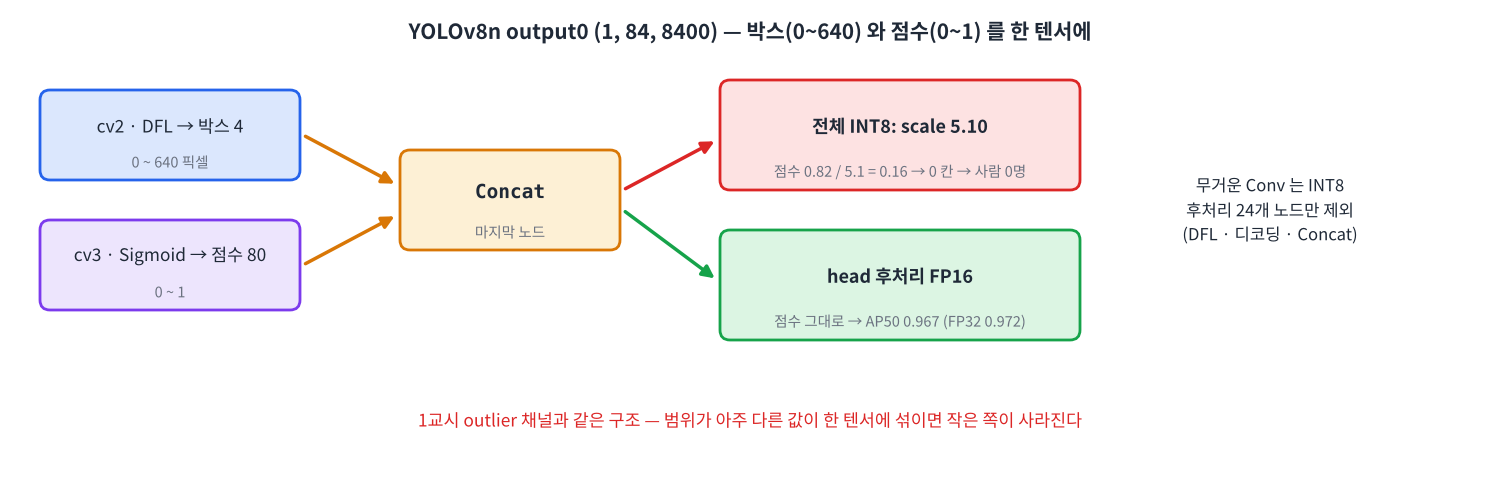

In [ ]:
#@title 🖼 그림 — 박스(0~640)와 점수(0~1)를 한 텐서에 — scale 하나로는 점수가 모두 0 이 된다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f6_head.png", embed=True, width=860))

In [ ]:
# ▶ 데이터 · 모델 셀 (2) — Penn-Fudan · YOLOv8n · VB Day 4 / OT Day 5 함수 (iou · nms · letterbox · decode · AP)
PF = "PennFudanPed"
if not os.path.exists(f"{PF}/PNGImages"):
    r = subprocess.run(["git", "clone", "-q", "--depth", "1", "https://github.com/swallan/PennFudanPed.git", PF])
    if r.returncode != 0:
        import zipfile
        urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "PennFudanPed.zip")
        zipfile.ZipFile("PennFudanPed.zip").extractall(".")
YOLO_ONNX = fetch("yolov8n.onnx")

def iou(box, boxes):
    box = np.asarray(box, float); boxes = np.asarray(boxes, float).reshape(-1, 4)
    x1 = np.maximum(box[0], boxes[:, 0]); y1 = np.maximum(box[1], boxes[:, 1])
    x2 = np.minimum(box[2], boxes[:, 2]); y2 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])
    return inter / (area(box) + area(boxes) - inter)

def iou_matrix(A, B):
    A = np.asarray(A, float).reshape(-1, 4); B = np.asarray(B, float).reshape(-1, 4)
    x1 = np.maximum(A[:, None, 0], B[None, :, 0]); y1 = np.maximum(A[:, None, 1], B[None, :, 1])
    x2 = np.minimum(A[:, None, 2], B[None, :, 2]); y2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aA = (A[:, 2] - A[:, 0]) * (A[:, 3] - A[:, 1]); aB = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
    return inter / (aA[:, None] + aB[None, :] - inter)

def nms(boxes, scores, iou_thr=0.5):
    boxes = np.asarray(boxes, float); scores = np.asarray(scores, float)
    order = np.argsort(-scores); keep = []
    while order.size > 0:
        i = order[0]; keep.append(i); rest = order[1:]
        order = rest[iou(boxes[i], boxes[rest]) <= iou_thr]
    return np.array(keep, dtype=int)

def letterbox(img, size=640, color=114):
    h, w = img.shape[:2]; r = min(size / h, size / w)
    nw, nh = round(w * r), round(h * r)
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    top, left = (size - nh) // 2, (size - nw) // 2
    out = np.full((size, size, 3), color, dtype=np.uint8); out[top:top + nh, left:left + nw] = resized
    return out, r, (left, top)

def to_input(img):
    lb, r, pad = letterbox(img)
    return (lb[..., ::-1].transpose(2, 0, 1)[None] / 255.0).astype(np.float32), r, pad

def decode_yolo(out, conf_thr=0.25, iou_thr=0.7, cls=0):
    p = np.asarray(out)[0].T                              # (8400, 84)
    boxes_c, cls_scores = p[:, :4], p[:, 4:]
    best, conf = cls_scores.argmax(1), cls_scores.max(1)
    m = (conf > conf_thr) & (best == cls)
    cx, cy, w, h = boxes_c[m].T
    boxes = np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], 1)
    keep = nms(boxes, conf[m], iou_thr)
    return boxes[keep], conf[m][keep]

def detect(frame, infer, conf=0.25, iou_thr=0.7):
    x, r, (pl, pt) = to_input(frame)
    boxes, scores = decode_yolo(infer(x), conf, iou_thr)
    boxes = (boxes - [pl, pt, pl, pt]) / r
    H, W = frame.shape[:2]
    boxes[:, [0, 2]] = boxes[:, [0, 2]].clip(0, W); boxes[:, [1, 3]] = boxes[:, [1, 3]].clip(0, H)
    return boxes, scores

def ap_from_pr(rec, prec):
    mrec = np.concatenate([[0.0], rec, [1.0]]); mpre = np.concatenate([[0.0], prec, [0.0]])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def match_detections(dets, gts, iou_thr=0.5):
    recs = []
    for i, d in enumerate(dets):
        for row in np.asarray(d, float).reshape(-1, 5):
            recs.append((row[4], i, row[:4]))
    recs.sort(key=lambda t: -t[0])
    used = [np.zeros(len(g), bool) for g in gts]; scores, tp = [], []
    for s, i, b in recs:
        ok = 0
        if len(gts[i]):
            o = iou(b, gts[i]); j = int(o.argmax())
            if o[j] >= iou_thr and not used[i][j]:
                used[i][j] = True; ok = 1
        scores.append(s); tp.append(ok)
    return np.array(scores), np.array(tp), sum(len(g) for g in gts)

def evaluate_ap(dets, gts, iou_thr=0.5):
    scores, tp, n_gt = match_detections(dets, gts, iou_thr)
    if len(tp) == 0:
        return 0.0
    ctp = np.cumsum(tp)
    return ap_from_pr(ctp / n_gt, ctp / np.arange(1, len(tp) + 1))

def map_50_95(dets, gts):
    return float(np.mean([evaluate_ap(dets, gts, t) for t in np.arange(0.5, 0.96, 0.05)]))

def parse_annotation(path):
    pairs = re.findall(r"\((\d+), (\d+)\) - \((\d+), (\d+)\)", open(path, encoding="latin-1").read())
    return np.array(pairs, dtype=np.float32).reshape(-1, 4)

img_paths = sorted(glob.glob(f"{PF}/PNGImages/*.png"))
gts = [parse_annotation(p.replace("PNGImages", "Annotation").replace(".png", ".txt")) for p in img_paths]
imgs = [cv2.imread(p) for p in img_paths]
def ort_infer(path, threads=0):
    """ONNX 파일 → x 를 받아 output0 을 돌려주는 함수 (TRTInfer 와 같은 모양)"""
    s = make_session(path, threads)
    return lambda x: s.run(None, {"images": x})[0]
yolo_fp32 = ort_infer(YOLO_ONNX)
with quiet():
    quant_pre_process(YOLO_ONNX, "yolov8n_pre.onnx")
print(len(imgs), "장 ·", sum(len(g) for g in gts), "명 | YOLOv8n 노드", len(onnx.load(YOLO_ONNX).graph.node), "개")

**▶ 예제 6-A (제공 코드 — 실행만)** 보정과 평가에 **같은 사진을 쓰지 않도록** Penn-Fudan 170장을 나눕니다. 인덱스가 4의 배수인 사진을 보정용 `CAL_IDX`, 나머지를 평가용 `EVAL_IDX` 로 하고, 보정용 사진을 한 장씩 `{"images": 입력}` 으로 내보내는 `YoloReader(idx)` 를 만듭니다 — Day 2 실습 4-1 의 `CifarReader` 와 같은 구조입니다.

> 이 셀은 **직접 구현이 아닙니다.** 그대로 실행하고, 출력과 아래 해설을 읽어 보세요.

In [ ]:
# ▶ 예제 6-A — 제공 코드 (그대로 실행)
CAL_IDX = [i for i in range(len(imgs)) if i % 4 == 0]
EVAL_IDX = [i for i in range(len(imgs)) if i % 4 != 0]

class YoloReader(CalibrationDataReader):
    def __init__(self, idx):
        self.idx = list(idx); self.rewind()
    def get_next(self):
        i = next(self.it, None)
        return None if i is None else {"images": to_input(imgs[i])[0]}
    def rewind(self):
        self.it = iter(self.idx)

r_ = YoloReader(CAL_IDX); first = r_.get_next()
print(f"보정 {len(CAL_IDX)}장 · 평가 {len(EVAL_IDX)}장 | 첫 입력 {first['images'].shape} {first['images'].dtype}")

In [ ]:
assert len(CAL_IDX) == 43 and len(EVAL_IDX) == 127 and not set(CAL_IDX) & set(EVAL_IDX)
r_.rewind(); n_ = 0
while r_.get_next() is not None: n_ += 1
assert n_ == 43 and first["images"].shape == (1, 3, 640, 640)
print("✅ 보정 43장 · 평가 127장 · 겹침 없음")

> 💡 **예제 6-A 해설** — 보정에 쓴 사진으로 평가하면 그 사진에 맞춰진 범위로 재는 셈이라 결과가 좋게 나올 수 있습니다 (7-1 에서 확인). 머신러닝의 학습 / 검증 분리와 같은 원칙입니다. YOLOv8n 입력은 배치 1 고정 (1, 3, 640, 640) 이라 한 장씩 내보냅니다. 전처리는 OT Day 5 의 letterbox · RGB · CHW · /255 그대로입니다.

**✍️ 직접 구현 6-1** `make_trt_int8` 로 YOLOv8n **전체**를 양자화해 `yolov8n_int8_all.onnx` 를 만들고, 평가용 첫 사진 (`imgs[EVAL_IDX[0]]`) 에서 FP32 와 INT8 이 찾은 사람 수 `n_fp32`, `n_all` 을 세세요. 그리고 `output0` 을 만드는 `DequantizeLinear` 의 scale `out_scale` 을 꺼내, 점수 범위 (0 ~ 1) 에 쓸 수 있는 정수 칸 수 `score_levels = 1 / out_scale` 을 구합니다. (양자화에 약 30초)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 6-1 — 실행할 때마다 하나씩
show_hint("6-1", "YG1ha2VfdHJ0X2ludDgoInlvbG92OG5fcHJlLm9ubngiLCAieW9sb3Y4bl9pbnQ4X2FsbC5vbm54IiwgWW9sb1JlYWRlcihDQUxfSURYKSlgIOKAlCDslb0gMzDstIguHuyCrOuejCDsiJg6IGBsZW4oZGV0ZWN0KGltMCwg7LaU66Gg6riwKVswXSlgLCBJTlQ4IOy2lOuhoOq4sOuKlCBgb3J0X2luZmVyKCJ5b2xvdjhuX2ludDhfYWxsLm9ubngiKWAuHmBvdXRwdXQwYCDsnYQg7Lac66Cl7ZWY64qUIOuFuOuTnDogYFtuIGZvciBuIGluIGcubm9kZSBpZiAib3V0cHV0MCIgaW4gbi5vdXRwdXRdWzBdYCDihpIg6re4IOuFuOuTnOydmCBgaW5wdXRbMV1gIOydtCBzY2FsZSDsnbTrpoQu")

In [ ]:
# ✍️ 직접 구현 6-1 — YOLOv8n 전체 양자화
im0 = imgs[EVAL_IDX[0]]
# TODO: yolov8n_int8_all.onnx 만들기
n_fp32, n_all = None, None     # TODO
dq_out = None                   # TODO: output0 을 만드는 노드
out_scale = None                # TODO
score_levels = None             # TODO
print(f"사람 FP32 {n_fp32}명 · INT8(전체) {n_all}명 | output0 scale {out_scale:.3f} → 점수 0~1 에 쓸 수 있는 칸 {score_levels:.2f} 개")

In [ ]:
assert dq_out.op_type == "DequantizeLinear" and n_fp32 > 0 and n_all == 0 and score_levels < 1
print(f"✅ 마지막 Concat 까지 양자화하면 점수가 모두 0 칸 → 사람 0명 (scale {out_scale:.2f})")

In [ ]:
#@title 🔒 정답 보기 6-1 — 강사가 알려 준 실습 6-1 잠금 코드를 입력하세요
show_answer("6-1", (
    "+mHMlfJYE4TgeN5Nc2zf8vZRHPsYaMVto1JsiIuCJ1SMZF7RG/xDJLYzx/neW8Elaksv+M4y/Q36la1GiY/C0LRF"
    "qRBh05ofzr4ek+qEfSFm2idvvLbFmfr4GGShmLBv/h9XtD4Ylt9kRDnf1QawGivX224PdWqk+7LRzy/nW1qqcB+o"
    "269RNGMal4ECj/G4+oxKTTzCc5HuK8gyj19boeJ/Hplx+mAeEg9Pj/S+6lds5dCM/mUuxboT32wHFH6NEEgXA2eG"
    "oYJErp6BWjdlthBGbV1mOuLpbwz4r/Gx6+tZN+Wqd12/9kge/eG4ZICZJwab6RalVulZNbRI9s8RQt4pS123Bfec"
    "fr0uxuti7DVSFqGHdIjjuTZVcexjn5BqIxlE48/hKpfA09NnuuGuoFMqlfjvIkQap8Gw6o9MhaoVVAOVnA/kp4Kj"
    "25tcfuLTtw7lze1yt7TIY231AEtFo0T266rhZW2T1et9TQanT/X9DQxblVdichiBmw+icnoA6J/lyTML1SYa6kpK"
    "mdaRD0rHuabyQrxP/C50+z4642Ia9no7baFQlG7v2dTBGqYCHFx/xr/eDYfURvvIMJW9qz8ierVLIPEZahx8NfU7"
    "yR1gwX4tybvl6csfp7iAIGjt5cZZZ5WSWvEsY1lLFmjIaRhQKZKb++Tvrx4mHCXR5qzOgj3OdbGWKpjYgHbMe96k"
    "SShLIzwADXKHE3AxfQ1dJ7zqOCRW0TDt1HLF84wAhF00EKNbkqtqThyAGerJbPo9rGcnXqQiozxQfQLqOMfO8P44"
    "HbJjn+6HH51R5O4UwiplO+tMHlUc4LnbErDCuR9k57kBPMrJJE9Ou6V4gqyXb3AzPX06WZPKnW7ay6C3S1EIy8uG"
    "IDE3O7A54W1rw+z3uGzEJQgRreS4lvYUWIvYA5+FdBg02v9VvGyGWA86xI5CI/7mVvHPnxI6BlVatCZAvHNa4yP6"
    "q3fcnO+Fvm3aZk1cG3LxBBjOA+59ORUjl6cH6N+RgCP0BSZZkKWU4EqB7sXDhK0OuoyYBueNtGJg9sAcVT5UlX8x"
    "KKKL2yFzP70l8sPoFcyEwjz8/0FnHjgdk5odQDP39BiPryDrXE65sD4PdukOGl4Ja44eoXi1rSOJtuIV4pEoxWTk"
    "TiFHXp5Oc04Fb550LFNiTmh0ogYLqu0nm7OsXORjkmpB1QL6XAaw8Xf32fz+8/+c5wYuAkenRVorBrlaahMNpR7A"
    "f1FJ6JLwBk3RcHxfVji419mGJpUSUKov6OzbvXztT6l2YTyODjB0VPqk2+l5+tNKeCJqM2c1xejZFGyQju8M2jw9"
    "F1oSxyE1spiq6GlAAH7dUUTZHSroU9d/4uVosQx7uylFMtaGf4WymimZHbPitTAJslQ1hls7utbEMlrdfXXc1aul"
    "iSYkF8C/NaX8TtLAdous62VKeviPp+2p8gxbXX8yJ7A="
))


**✍️ 직접 구현 6-2** Detect head (`/model.22/`) 중 **cv2 · cv3 갈래의 Conv 를 뺀 나머지** (DFL · 디코딩 · Concat 등 후처리) 노드 이름 목록 `head` 를 만들고, 이것을 제외해 `yolov8n_int8.onnx` 를 만드세요. 같은 사진에서 FP32 박스와 짝지은 IoU 의 중앙값 `head_iou` 를 구합니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 4개).

In [ ]:
#@title 💡 힌트 6-2 — 실행할 때마다 하나씩
show_hint("6-2", "YGdfeSA9IG9ubngubG9hZCgieW9sb3Y4bl9wcmUub25ueCIpLmdyYXBoYC4e7KGw6rG0OiDsnbTrpoTsnbQgYC9tb2RlbC4yMi9gIOuhnCDsi5zsnpHtlZjqs6AsIGByZS5tYXRjaChyIi9tb2RlbC4yMi9jdlsyM11cLlxkLyIsIOydtOumhClgIOydtCDslYTri4wg6rKDLh5gbWFrZV90cnRfaW50OCguLi4sIGV4Y2x1ZGU9aGVhZClgIOKGkiBgeW9sb19pbnQ4ID0gb3J0X2luZmVyKCJ5b2xvdjhuX2ludDgub25ueCIpYC4e7KedIElvVTogYGlvdV9tYXRyaXgoSU5UOCDrsJXsiqQsIEZQMzIg67CV7IqkKS5tYXgoMSlgIOydmCDspJHslZnqsJIu")

In [ ]:
# ✍️ 직접 구현 6-2 — Detect head 후처리만 FP16 으로 남기기
g_y = onnx.load("yolov8n_pre.onnx").graph
head = None        # TODO
# TODO: yolov8n_int8.onnx 만들기
yolo_int8 = None   # TODO
b32, b8 = None, None   # TODO: im0 의 박스
head_iou = None        # TODO
print(f"head 제외 노드 {len(head)}개 | 사람 FP32 {len(b32)}명 · INT8 {len(b8)}명 | 짝 IoU 중앙값 {head_iou:.3f} | {trt_check('yolov8n_int8.onnx')}")

In [ ]:
assert 15 <= len(head) <= 40 and not any(re.match(r"/model.22/cv[23]", n) for n in head) and "/model.22/Concat_3" in head
assert trt_check("yolov8n_int8.onnx")["ok"] and len(b8) > 0 and head_iou > 0.9
print(f"✅ Detect head 후처리만 빼니 사람을 다시 찾는다 (IoU {head_iou:.3f})")

In [ ]:
#@title 🔒 정답 보기 6-2 — 강사가 알려 준 실습 6-2 잠금 코드를 입력하세요
show_answer("6-2", (
    "VMv61wkVSKp8bnuhP14wZgoazUbOclIlrTp+R1P1sxypglyyFzYv2SzAZzvfG2QUD7P5Kvo1dEIw/sESbAgjVZcp"
    "4WbIdNSNkVbUDy+qkx0RKBQPWbtvn+oXe1F8fVXYjPnslAx0ds5ZReeiGnEVk/Rv5c1dxMkAawUYsCSYcKbOcOmh"
    "puvcYQ+lzlLn3NNIBKzskViDmWMT5KYStK+mRnOZYthIKnTvw5yLL3WMQqABVSp5ZePWjRu5ofQ+M/qR/WCpsm5T"
    "DlgwC3L3OTF9mP2WGLSfkAaDgSqsufZrER8fMXXCCR+xcT+iU6GsFbDTesQT2sQg7nS0LxD732vwPF1q2B5VtbwA"
    "aOACRFOL9z/Qj/PV0UsT4aVaAAP9VPrcNU/NBRqKBmx0vuIMHxwKTXIN68xY0KcZVZl4RSnAXUiR1WNZ2cjs5iLg"
    "eesH9hOCfs8Mh8UdCi12AUSwICt3HcDRDK5GmHeOaEdmPAZ9TAb0w+SXDQkdoevffmOENLBoSLYCjg7XWIACoN08"
    "JqI8N2tLtGdynWtLFFhFhD607r9lhFCESc2kdM6lGZyGOfn93Kc4zIF2nrIpBVfk40o6QuCcDB/48BIR5jUaxw4q"
    "fAhMmEOJdtJ/7NSQlwAXffY1nCzU/RglBvFIpJPftOC/6qoi10basGV946nWQIa7orZAt3zKP5auLpcnt6cnoHsl"
    "qyitWuvFtuBZkdzkdWQBIAogSCb674ufhGLmon7rCqy7JpopNcIEx1TtSsKLOZfRdKqAVMm0GHvyRscQT1rhytss"
    "LKwcUsqpiid+qNEvjlYuZ20VKCPEfSMqqpqx9l4DM64eEaYeAmOR0MtlcDkBI8ZVpfsZFZBkyBhPsvS1/9MGLJGP"
    "9oLtUGEwbhUj/ZSiS1z3f3pOq1cWCnQ4DJYcqDYSqzZ55Jmo5s5OtI5SBFCsgoMvOI1JXMDAbKHR/+0Mf3aHn6te"
    "LmfjOUkyYPuhUuTuettpkWWioVn2mMfxvAMtw7Vw4sDpFIoqc/j7IYk/fgJN6rL3HqQ7Og7BxoplzHN1P4UvhlQc"
    "Zu7YTa2onSgTZiFvwkJp+P7YREpxM+av+r3OaG+G2ZL5nX7wrcPLJok4Yxowsu+8qcN8MPPcvElFt24EySEQYfoC"
    "YgTx/kHInJy4Q0o4GQ41oNHqgmvC3PODKiCrWGhi16242VoDHKs26iiQFUVv6Ezlg3PkYi8fCqp4QljL0SQM72aG"
    "2WZVQ+IV/yQpqp7VfB9PcNJucpk+1mZ2juOjiMc5CjsCQeedJzqQJSGAN/fFxTdkTKRWm+gSigm2pq8Moe+O4Ef2"
    "f874XNEYQgP/dYqko5UXUFGldvKoLPGt6qPH6cDuTOTdseRWBIV+a5CBVJxFRt1mB0S6MmX5mqUllJIfYfTnCXbR"
    "eiHq"
))


#### 📌 6교시 정리

- 탐지 모델의 출력은 **범위가 다른 값을 한 텐서에** — 마지막 Concat 을 양자화하면 점수가 0 이 된다 (사람 0명).
- Detect head 후처리 (DFL · 디코딩 · Concat) 를 빼고, 무거운 Conv 만 INT8 → `yolov8n_int8.onnx`.
- 보정 43장 / 평가 127장 — **같은 사진을 두 번 쓰지 않는다.**

## 7교시 — 정확도 검증: 보정 / 평가 분리 · mAP

탐지 모델의 정확도는 **AP@0.5** 와 **mAP@0.5:0.95** 로 잽니다 (VB Day 4 의 `iou_nms_map.py` 함수, 위 데이터 셀에 들어 있음). 박스를 낮은 conf (0.01) 까지 모두 받아 precision-recall 곡선을 그린 뒤 면적을 구합니다.

양자화 검증의 규칙:

1. **평가 세트는 보정에 쓰지 않은 사진**으로.
2. FP32 · FP16 · INT8 을 **같은 함수 · 같은 사진**으로.
3. 기준은 'FP32 대비 몇 %p 떨어졌나'.

> 🎬 **애니메이션** [D3-7 보정 / 평가 분리와 mAP](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-7)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

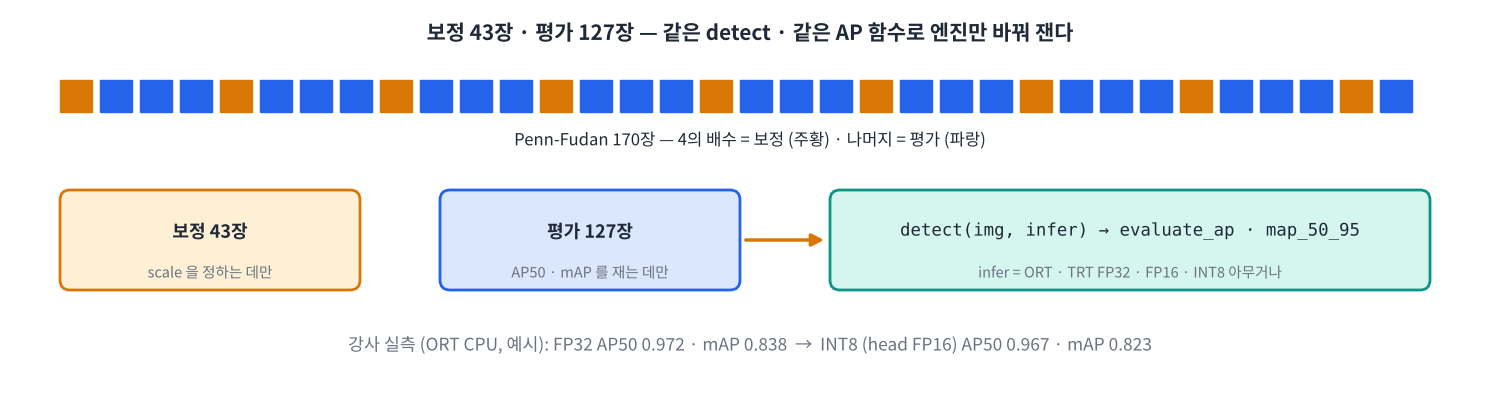

In [ ]:
#@title 🖼 그림 — 보정 43장 · 평가 127장 — 같은 detect · 같은 AP 함수로 엔진만 바꿔 잰다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f7_split.png", embed=True, width=860))

**✍️ 직접 구현 7-1** 추론기 `infer` 와 사진 인덱스 목록을 받아 `(AP50, mAP50-95)` 를 돌려주는 `eval_map(infer, idx)` 를 만드세요 (detect 는 `conf=0.01`). FP32 · INT8 (head 제외) 을 평가용으로, INT8 을 **보정용 사진으로도** 재서 `map_df` (열 `model`, `split`, `AP50`, `mAP`) 를 만듭니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-1 — 실행할 때마다 하나씩
show_hint("7-1", "7IKs7KeE66eI64ukIGBiLCBzID0gZGV0ZWN0KGltZ3NbaV0sIGluZmVyLCBjb25mPTAuMDEpYCDihpIgYG5wLmNvbmNhdGVuYXRlKFtiLCBzWzosIE5vbmVdXSwgMSlgIChOLCA1KS4e7KCV64u1IOuqqeuhneuPhCDqsJnsnYAg7J24642x7Iqk66GcOiBgW2d0c1tpXSBmb3IgaSBpbiBpZHhdYC4eYGV2YWx1YXRlX2FwKGRldHMsIGcpYCDqsIAgQVA1MCwgYG1hcF81MF85NShkZXRzLCBnKWAg6rCAIG1BUC4gNOqwgOyngCAo66qo6424IMOXIOyEuO2KuCkg66W8IO2WieycvOuhnC4=")

In [ ]:
# ✍️ 직접 구현 7-1 — mAP 함수와 보정 / 평가 비교
def eval_map(infer, idx):
    # TODO: (AP50, mAP)
    pass

rows = []
# TODO: (FP32, eval) (INT8, eval) (INT8, calib) (FP32, calib)
map_df = pd.DataFrame(rows)
display(map_df.round(4))

In [ ]:
m_ = map_df.set_index(["model", "split"])
assert m_.loc[("FP32", "eval"), "AP50"] > 0.95 and abs(m_.loc[("INT8", "eval"), "AP50"] - m_.loc[("FP32", "eval"), "AP50"]) < 0.02
assert abs(m_.loc[("INT8", "eval"), "mAP"] - m_.loc[("FP32", "eval"), "mAP"]) < 0.03
print(f"✅ 평가 127장 — AP50 {m_.loc[('FP32', 'eval'), 'AP50']:.3f} → {m_.loc[('INT8', 'eval'), 'AP50']:.3f} · mAP {m_.loc[('FP32', 'eval'), 'mAP']:.3f} → {m_.loc[('INT8', 'eval'), 'mAP']:.3f}")

In [ ]:
#@title 🔒 정답 보기 7-1 — 강사가 알려 준 실습 7-1 잠금 코드를 입력하세요
show_answer("7-1", (
    "IrUy0MA2+VheLV+Otn145oc7+N+fPFNgA6l/nXKfeKy8KUdD1Zsa98qOwt+lsMcDbUnDw/XUUrKPewdVHyam6NJu"
    "JXa96GgBUuH86Qr2X+Lw+AIxTga8NR/Zvyd5HNN7L7BeigyU5eN/JOFzWHc3WWhoqg0vdkB9UMeVTqYGUU1V9lxH"
    "Hn5CZZLkTAZRQtqqF0pVrccbSwDTGEXed/5KKU76+Y1sBCzkErzXANnr3sN0Lve6MrHE1h8Y35Rz0GLt+3ameqGo"
    "D1cKqAnyLjaLQGZRVLcAiFIn1QF2iCGovB6LTuZYMbxnsRQKkenHRSHiAYGhQ8zwjMvLx6hZ12Q2xebzaZuMMFxT"
    "Lr+DT84yBLhwBHLOi5g/N25LIkaMmZpBHHnsJMHUNtmpxWmQdEcA69hOh+d0JSb918/MoLCok7xgt1+sLBM2yW3c"
    "Vm5SsTk/qvAzzhJpXFp7EeAvf4SaQdo176m61whX16gFtx2t+NlmleLr1HRzcqPDoLlBPFzKl4PV4g0gpWatRw2N"
    "JxUdFxCaXeTEcLx94qgI28yZYoWCvA+nfBuaWyuosic9gl/yykwA4PQ8OfxUwxaA7/hQ995bPxHnMuR66/aWKchE"
    "4it/ScD6rOFIKa0x6RCbR5qF1jOvIKmVQjgv3TBkZwvs0gGBCd/Lw1N27i1uVmxFQf/3HZwPcvv52NEV30OQ8cVQ"
    "zmnpLXjsXz2hDBoQdMwXbgnilkNbiQdnWIib7KN7wp8wZmfCuRdxZhdT8yRM1dRThikf0pkO9H8plzKWJKs2urcM"
    "tTDMQ3Sa0831nd3akaaWIshzDw6Oy/VwwBMXSvoF+q/l1uo8Nol8U+VjGtP5cPvXyRWlwVVQ7BNwI4lajPGeCv0N"
    "tuWoYHMcxMW11tsDcTvyTiaO7FVQGs46i7AL2JO/kGKltfHaNby60iUGwt2T7Ucup/zxIGnciX0fRuPV69iJ/3Ev"
    "USFH1/sbXPoU6pgN3WrHzVnoQZCNZMsMq5HQ/XA/XbtznoK1XTDNcsWhgrLNpFw38SX0n1k6gNdHFsuTZ4NZGYmg"
    "qo/2VcZjGt8GntOvGVi0MKhnvD7anGXZ5gMWdZYSzk4EfqgDdlxmWCnZIo1Z+cijSq8/1bKYh6z98rsgazxNxEyM"
    "dBsPhlUMdJEDnA6o9LBLuyVDrapkWGgPtS5e3MsITbX/s6Gx6E9a5Wt13YHWay8XN8e728kVQYXRKoll5UQgbpZu"
    "pps4cW/cblqqVZyNM/UOweihoeW4JsyTCR1zCKsTDVcE9ueNQ7JZ1RnKnlvzTbHsSxVAgG8MPMutPwgnwWaB3hoS"
    "bJUArFqZf1/ABVCD4VTGoX46z0XgMOrqmEeBpvHAVphhQARhaeilJzCY6kXuH86eGnJWoxYaFLEG2lnW/M2P1vSz"
    "9tVLuack1RybU5ZHpw9i4AhSDaDR52MCiZ4eC2WpNfrJiSmpYQ=="
))


**✍️ 직접 구현 7-2** 정밀도 이름과 ONNX 를 받아 **같은 모양의 추론기**를 돌려주는 `make_infer(prec, onnx_path, fp16, int8)` 를 만드세요. GPU 이면 `build_once` 로 `yolov8n_{prec}.engine` 을 만들어 `TRTInfer` 를, 아니면 FP16 은 `None`, 나머지는 `ort_infer(onnx_path)` 를 돌려줍니다. 이것으로 **FP16 · INT8 엔진의 평가용 mAP** 를 재 `trt_map_df` (열 `prec`, `backend`, `AP50`, `mAP`) 를 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 7-2 — 실행할 때마다 하나씩
show_hint("7-2", "R1BVOiBgVFJUSW5mZXIoYnVpbGRfb25jZShvbm54X3BhdGgsIGYieW9sb3Y4bl97cHJlYy5sb3dlcigpLnJlcGxhY2UoJy0nLCAnXycpfS5lbmdpbmUiLCBmcDE2PWZwMTYsIGludDg9aW50OCkpYC4eQ1BVOiBGUDE2IOydtOuptCBgTm9uZWAsIOyVhOuLiOuptCBgb3J0X2luZmVyKG9ubnhfcGF0aClgLh5GUDE2IOydgCBgWU9MT19PTk5YYCArIGZwMTYsIElOVDgg7J2AIGB5b2xvdjhuX2ludDgub25ueGAgKyBmcDE2ICsgaW50OC4g7LaU66Gg6riw6rCAIE5vbmUg7J2066m0IEFQIOuKlCBOYU4u")

In [ ]:
# ✍️ 직접 구현 7-2 — 같은 모양의 추론기 만들기
def make_infer(prec, onnx_path, fp16=False, int8=False):
    # TODO
    pass

rows = []
# TODO: FP16 · INT8 의 평가용 AP50 · mAP
trt_map_df = pd.DataFrame(rows)
display(trt_map_df.round(4))

In [ ]:
t_ = trt_map_df.set_index("prec")
assert list(trt_map_df.prec) == ["FP16", "INT8"] and abs(t_.loc["INT8", "AP50"] - map_df.AP50[0]) < 0.03
assert (not TRT_OK and np.isnan(t_.loc["FP16", "AP50"])) or (TRT_OK and abs(t_.loc["FP16", "AP50"] - map_df.AP50[0]) < 0.01)
print(f"✅ {BACKEND} INT8 AP50 {t_.loc['INT8', 'AP50']:.3f}" + (f" · FP16 {t_.loc['FP16', 'AP50']:.3f}" if TRT_OK else " (GPU 없음 — FP16 생략)"))

In [ ]:
#@title 🔒 정답 보기 7-2 — 강사가 알려 준 실습 7-2 잠금 코드를 입력하세요
show_answer("7-2", (
    "kku/Q4WmrSAsX505psIV4mm15B4BbwXkWiiKz9xh1FHA/+LBFyCnyRezE0FHi9zlEoTlTl0ad/JkwruiMqiGlQYB"
    "SFBpCihLX12FXBpdpLiQ8WxA56Kpe5m43swUrHA3THimQGnckgeDmZNQChdghQ5Sc9NR5WiDMkDHEJllUD6ej2LT"
    "WlVHr2YKd9dx2vf6ftYazqNpf033B7eZ1/bV2/4bCrzrI+z6RxByV0EpS9yX+Yp6ZHCxOp5cmHAiVVcofLHa6kPY"
    "MUOlGmUaVzCv7RFv/jXhaP9cGO1EdFLoBGXbOJ/nyN+d2eUWAAtMo08YZnoWpngEAWBgfn5slaoejO6XTAo+Zcx8"
    "kSYDp8JG860x5G78fHT6Rr4xUx+6Blb2sCDaKw6XidIYHC9iSyfjAfeNCg73xJxec3xo9dNpMUNSOBPyv7T4j4kY"
    "jjXZRCCsNUPrcXf/3IbekEGPROYMAMnod7KvEExopaOMKzhB8MJsQjWCSpRxY6rzU4cMg0BunqXpOHegkzpYagxc"
    "ctPPPEw1p9b/9YS5W28nZKz9z16rotGDKzJ9tDfOuaiBNA6rLlto8iqJ3LluTWUwyELa3BlDEUDPeNUmopz8UGVZ"
    "3qcEyDlvgzxfqJFGOeHmYK9xMXakF0+YpMnrD0MSxWL3RUoSb4ju60CRMVY8pVFhbtstC2S8fHZHl1qZ1BRnRhw7"
    "7DtZL6eoK+T6lKeTP3WRf1udsZqheqMzkbvi+yEGv2xjdX+pQbGGUtHckwS1e3eOypyMJbzBT86JcrIJEJ4cRAQw"
    "t3oIDs7rkd2SkYoqjmYdCZrath2uh4C7xVwWXfZ1WINIRIVNtteqxKXe6zc0ZeUY3t51QBIEsvuU7I5zGWMKob2q"
    "m3iIFjranGpMYfzxMparVdxKl0ClxIMJI5/XU4U0AvbYred8p/6XKJGdQp1ziSAKJfuCHguGLJGPUzlCTx+AsNR4"
    "NP7yPFScMsjPMK8ZVFS+uOUkWR2La+Gia0nEIS/d0UTDgIdlU4vSUGCsUdrw4DuPBl5oZEo4ZK4NLDbEVZ8qMOAT"
    "4Ken8rVfFw+5uxpL79+fsQzC8WVvb40aZJAdmtmtAj4whhxyJrqCM8uNFQzmJFVB+qt22Rx5SHJfgs0q0GWqYYTA"
    "Thw8/pDUStWl/P9XFqMjKO8cubYSCb3xR3nPdK8GBlG+MqXXTEwt2meDV3Vzw4N9CXMNhYwRh6nVMNeyfDPhIwR9"
    "zUASFx+DTMEP5PrOEcuz7fxBIoJU/hg4Liq4ZVqehsgJVTCbHtYs3gQx2DemwVrktF/EDiLgvIgSwhU6JvqZQpcs"
    "iOjWpQY1Jx25QktBzuBEIVwWX/3OuQTLiIaN5p9HubPZiR5ycQica52hFBgn/fJxZBq4u2U81/IkufjU2c8UN5s="
))


#### 📌 7교시 정리

- 탐지 양자화 검증 = **같은 detect · 같은 AP 함수**, **보정에 쓰지 않은 사진**.
- YOLOv8n INT8 (head FP16) 은 AP50 손실 1%p 안팎 · mAP 손실 1~2%p (예시) — mAP@0.5:0.95 가 더 예민하다.
- `make_infer` 하나로 FP32 · FP16 · INT8 엔진을 바꿔 끼운다 → 8교시 심사서.

## 8교시 — 미니 프로젝트: INT8 배포 심사서

**상황** — 침입 감지 카메라(OT Day 5)를 GPU 장치에 배포합니다. YOLOv8n 엔진 **4개 (FP32 · FP16 · INT8 · INT8-mixed)** 를 같은 조건으로 재서 **배포 심사서**를 쓰고 하나를 추천하세요.

| 엔진 | ONNX | 플래그 |
|---|---|---|
| FP32 | `yolov8n.onnx` | — |
| FP16 | `yolov8n.onnx` | FP16 |
| INT8 | `yolov8n_int8.onnx` (head 제외) | INT8 + FP16 |
| INT8-mixed | `yolov8n_int8_mixed.onnx` (head + **첫 Conv + 마지막 출력 Conv 6개** 제외) | INT8 + FP16 |

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | INT8-mixed 모델 만들기 | 20 |
| 2 | `measure(...)` — 지연 · FPS · AP50 · mAP · 크기 | 20 |
| 3 | 엔진 4개 심사표 `review_df` | 20 |
| 4 | 규칙대로 추천 → `deploy_review.csv` · `qp_baseline.csv` | 20 |
| 5 | FP32 와 추천 엔진의 박스 비교 (IoU) | 10 |
| 6 | 심사서 의견 (마크다운) | 10 |

> 미니 프로젝트에는 **정답 보기 셀이 없습니다.** GPU 가 없으면 FP16 행은 비워 두고 ONNX Runtime CPU 로 잰 값으로 채점합니다. 채점 셀을 실행하면 자동 채점 점수와 **정답 열람 기록**이 나옵니다 (과제 6 은 강사 채점).

> 🎬 **애니메이션** [D3-8 배포 심사서](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/animation.html#d3-8)
> 애니메이션은 **이 교시의 노트북 순서 그대로**입니다 — 단계마다 먼저 **예측**을 고르고, 노트북에서 **직접 구현**해 확인합니다. 개념 점검은 하루가 끝난 뒤 **복습 퀴즈**로 한 번에 합니다.

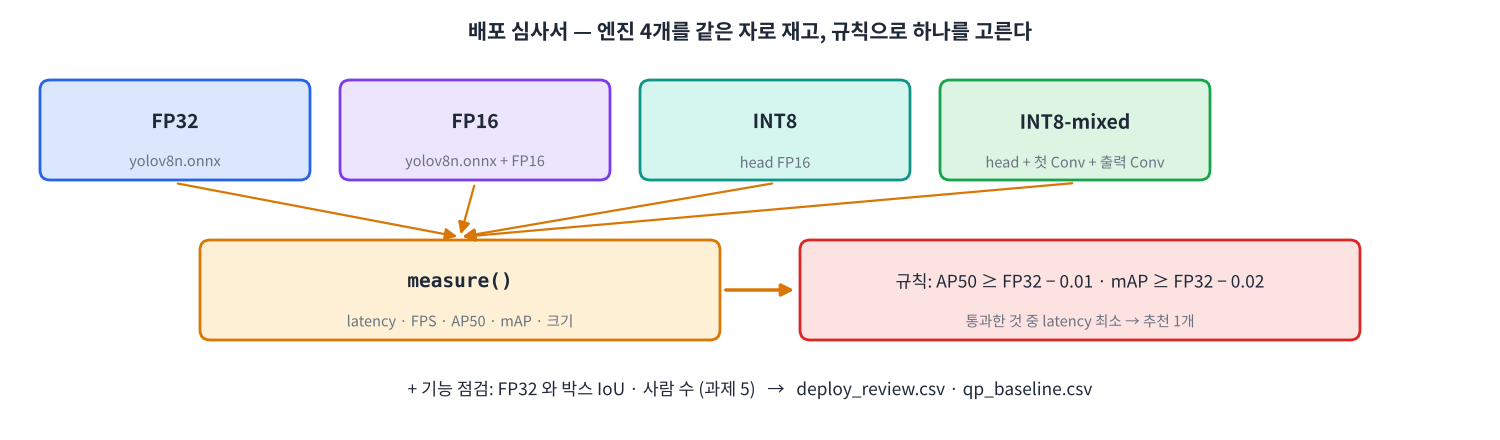

In [ ]:
#@title 🖼 그림 — 배포 심사서 — 엔진 4개를 같은 자로 재고, 규칙으로 하나를 고른다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/QP-day3/img/f8_review.png", embed=True, width=860))

**과제 1 (20점)** `head` 에 **첫 Conv** (`/model.0/conv/Conv`) 와 **Detect 의 마지막 출력 Conv 6개** (`/model.22/cv2.0/cv2.0.2/Conv` 처럼 `cv2.i.2` · `cv3.i.2`) 를 더한 `mixed_nodes` 를 만들고, 이것을 제외한 `yolov8n_int8_mixed.onnx` 를 만드세요.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-1 — 실행할 때마다 하나씩
show_hint("8-1", "7Lac66ClIENvbnYgNuqwnDogYHJlLm1hdGNoKHIiL21vZGVsLjIyL2N2WzIzXVwuXGQvY3ZbMjNdXC5cZFwuMi9Db252JCIsIG4ubmFtZSlgLh5gbWl4ZWRfbm9kZXMgPSBoZWFkICsgWyIvbW9kZWwuMC9jb252L0NvbnYiXSArIGxhc3RfY29udnNgLh5gbWFrZV90cnRfaW50OCgieW9sb3Y4bl9wcmUub25ueCIsICJ5b2xvdjhuX2ludDhfbWl4ZWQub25ueCIsIFlvbG9SZWFkZXIoQ0FMX0lEWCksIGV4Y2x1ZGU9bWl4ZWRfbm9kZXMpYC4=")

In [ ]:
# ✍️ 과제 1 — INT8-mixed 모델
last_convs = None    # TODO
mixed_nodes = None   # TODO
# TODO: yolov8n_int8_mixed.onnx 만들기
print(f"제외 노드 {len(mixed_nodes)}개 | {trt_check('yolov8n_int8_mixed.onnx')}")

**과제 2 (20점)** `measure(prec, onnx_path, fp16, int8)` 이 `{"prec", "backend", "latency_ms", "fps", "AP50", "mAP", "size_mb"}` 사전을 돌려주게 완성하세요. `make_infer` 로 추론기를 만들고, 지연 시간은 평가용 첫 사진의 입력 하나로 `bench_fn` (GPU 이면 `n=200, warm=20`, CPU 이면 `n=10, warm=2`), 크기는 엔진 파일 (GPU) 또는 ONNX 파일 (CPU) 의 MB. 추론기가 `None` 이면 숫자 값은 모두 `NaN`.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-2 — 실행할 때마다 하나씩
show_hint("8-2", "YGYgPSBtYWtlX2luZmVyKHByZWMsIG9ubnhfcGF0aCwgZnAxNiwgaW50OClgIOKAlCBOb25lIOydtOuptCDsiKvsnpDrpbwg66qo65GQIGBucC5uYW5gIOycvOuhnC4e7J6F66ClOiBgeCA9IHRvX2lucHV0KGltZ3NbRVZBTF9JRFhbMF1dKVswXWAsIOyngOyXsDogYGJlbmNoX2ZuKGxhbWJkYTogZih4KSwgbj0yMDAgaWYgVFJUX09LIGVsc2UgMTAsIHdhcm09MjAgaWYgVFJUX09LIGVsc2UgMilgLh7soJXtmZXrj4Q6IGBldmFsX21hcChmLCBFVkFMX0lEWClgLiDtgazquLAg7YyM7J28OiBHUFUg66m0IG1ha2VfaW5mZXIg6rCAIOunjOuToCDsl5Tsp4Qg7J2066aELCBDUFUg66m0IG9ubnhfcGF0aC4=")

In [ ]:
# ✍️ 과제 2 — 엔진 하나 재기
def measure(prec, onnx_path, fp16=False, int8=False):
    # TODO: {"prec", "backend", "latency_ms", "fps", "AP50", "mAP", "size_mb"}
    pass

print(measure("INT8", "yolov8n_int8.onnx", True, True))

**과제 3 (20점)** 엔진 4개 (위 표) 를 `measure` 로 재서 `review_df` 를 만드세요. 행 순서는 FP32 · FP16 · INT8 · INT8-mixed, 열은 과제 2 의 7개. (GPU 이면 빌드에 수 분, CPU 이면 약 1~2분)

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 2개).

In [ ]:
#@title 💡 힌트 8-3 — 실행할 때마다 하나씩
show_hint("8-3", "U1BFQyA06rCcICjsoJXrsIDrj4QsIE9OTlgsIGZwMTYsIGludDgpIOulvCDtkZwg6re464yA66GcIOyggeyKteuLiOuLpC4eYHBkLkRhdGFGcmFtZShbbWVhc3VyZSgqcykgZm9yIHMgaW4gU1BFQ10pYC4=")

In [ ]:
# ✍️ 과제 3 — 심사표
SPEC = None        # TODO: [("FP32", YOLO_ONNX, False, False), ...] 4개
review_df = None   # TODO
display(review_df.round(4))

**과제 4 (20점)** 추천 규칙: **AP50 ≥ FP32 AP50 − 0.01 이고 mAP ≥ FP32 mAP − 0.02** 인 엔진 중 **latency_ms 가 가장 작은 것**. 추천 엔진의 `prec` 를 `recommend` 에 담고, `review_df` 에 `pass` (규칙 통과 여부) · `recommend` (추천 여부) 열을 더해 `deploy_review.csv` 로 저장한 뒤, 4개 행을 `qp_baseline.csv` 에 `day="Day3"`, `model="yolov8n_<prec>"` 로 추가하세요 (열: `day, model, quant, size_kb, acc, mean_ms, p95_ms, fps_b32` — acc 에는 AP50, quant 에는 `f"{prec} ({backend})"`, 없는 값은 NaN).

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-4 — 실행할 때마다 하나씩
show_hint("8-4", "RlAzMiDtlok6IGBmMzIgPSByZXZpZXdfZGYuc2V0X2luZGV4KCJwcmVjIikubG9jWyJGUDMyIl1gLiDthrXqs7wg7KGw6rG0IOuRkCDqsJzrpbwgYCZgIOuhnC4e7LaU7LKcOiDthrXqs7ztlZwg7ZaJIOykkSBgc29ydF92YWx1ZXMoImxhdGVuY3lfbXMiKS5pbG9jWzBdLnByZWNgLh5iYXNlbGluZSDtlok6IGByZXZpZXdfZGYuaXRlcnR1cGxlcygpYCDroZwg64+M66mwIOyCrOyghOydhCDrp4zrk6Tqs6AsIOq4sOyhtCBjc3Yg6rCAIOyeiOycvOuptCBgcGQuY29uY2F0YCDrkqQgYGRyb3BfZHVwbGljYXRlcyhzdWJzZXQ9WyJkYXkiLCAibW9kZWwiXSwga2VlcD0ibGFzdCIpYC4=")

In [ ]:
# ✍️ 과제 4 — 규칙대로 추천 · 저장
recommend = None   # TODO
# TODO: pass · recommend 열, deploy_review.csv, qp_baseline.csv 에 4행
print("추천:", recommend)
display(review_df.round(4))

**과제 5 (10점)** 평가용 처음 20장에서 FP32 와 **추천 엔진**의 박스를 짝지어 (각 추천 박스의 FP32 박스와의 최대 IoU) 모은 뒤 중앙값 `pair_iou_med` 와 사람 수 차이의 합 `count_diff` (|FP32 명수 − 추천 명수| 의 합) 를 구하세요. 추천이 FP16 이 아닌데 GPU 가 없으면 ORT 로, 추천 엔진의 추론기는 `make_infer` 로 만듭니다.

> 막히면 아래 **💡 힌트** 셀을 실행하세요 — 실행할 때마다 힌트가 하나씩 더 나옵니다 (모두 3개).

In [ ]:
#@title 💡 힌트 8-5 — 실행할 때마다 하나씩
show_hint("8-5", "7LaU7LKcIOyXlOynhOydmCBTUEVDIOydhCDssL7slYQgYGZfcmVjID0gbWFrZV9pbmZlcigqc3BlYylgLh7sgqzsp4Trp4jri6QgRlAzMiDCtyDstpTsspzsnZgg67CV7IqkIOKGkiDsgqzrnowg7IiYIOywqOydtCDsoIjrjJPqsJLsnYQg642U7ZWY6rOgLCDrkZgg64ukIOyeiOycvOuptCBgaW91X21hdHJpeCjstpTsspwsIEZQMzIpLm1heCgxKWAg7J2EIOumrOyKpO2KuOyXkCDrjZTtlanri4jri6QuHuykkeyVmeqwkjogYGZsb2F0KG5wLm1lZGlhbihpb3VzKSlgLg==")

In [ ]:
# ✍️ 과제 5 — FP32 vs 추천 엔진 박스 비교
f_rec = None                 # TODO
ious, count_diff = [], 0
# TODO: EVAL_IDX[:20]
pair_iou_med = None          # TODO
print(f"추천 {recommend} vs FP32 — 짝 IoU 중앙값 {pair_iou_med:.3f} · 사람 수 차이 합 {count_diff}")

### 과제 6 — 배포 심사서 의견 (10점)

아래 셀에 답을 쓰세요 (각 2~3줄).

1. **추천 엔진**과 근거 3가지 (속도 · 정확도 · 크기 숫자로).
2. INT8 (head 제외) 과 INT8-mixed 의 차이가 측정 잡음보다 큰가요? 어떻게 확인하면 좋을까요?
3. INT8 을 전체 양자화했다면 (실습 6-1) 어떤 사고가 났을까요? 이 심사서에 어떤 점검 항목을 추가해야 할까요?
4. 이 결과를 Jetson (실제 배포 장치) 에 그대로 써도 될까요? 무엇을 다시 해야 하나요?

✍️ *여기에 답을 쓰세요.*

### 채점 셀

In [ ]:
score = 0
try:
    assert trt_check("yolov8n_int8_mixed.onnx")["ok"] and len(mixed_nodes) == len(head) + 7 and "/model.0/conv/Conv" in mixed_nodes
    g_m = onnx.load("yolov8n_int8_mixed.onnx").graph
    prod_ = {o: n for n in g_m.node for o in n.output}
    assert all(n.input[1] not in prod_ or prod_[n.input[1]].op_type != "DequantizeLinear" for n in g_m.node if n.name == "/model.0/conv/Conv")
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", repr(e))
try:
    m1 = measure("INT8", "yolov8n_int8.onnx", True, True)
    assert set(m1) == {"prec", "backend", "latency_ms", "fps", "AP50", "mAP", "size_mb"} and m1["latency_ms"] > 0 and abs(m1["fps"] * m1["latency_ms"] - 1000) < 1
    assert abs(m1["AP50"] - eval_map(make_infer("INT8", "yolov8n_int8.onnx", True, True), EVAL_IDX)[0]) < 1e-9
    score += 20; print("✅ 과제 2  +20")
except Exception as e: print("❌ 과제 2", repr(e))
try:
    assert list(review_df.prec) == ["FP32", "FP16", "INT8", "INT8-mixed"]
    assert {"backend", "latency_ms", "fps", "AP50", "mAP", "size_mb"} <= set(review_df.columns) and review_df.AP50.drop(index=1).notna().all()
    assert TRT_OK == review_df.AP50.notna().all()
    score += 20; print("✅ 과제 3  +20")
except Exception as e: print("❌ 과제 3", repr(e))
try:
    f_ = review_df.set_index("prec").loc["FP32"]
    ok_ = review_df[(review_df.AP50 >= f_.AP50 - 0.01 - 1e-9) & (review_df.mAP >= f_.mAP - 0.02 - 1e-9)]
    assert recommend == ok_.sort_values("latency_ms").iloc[0].prec and review_df["recommend"].sum() == 1
    rv_ = pd.read_csv("deploy_review.csv"); bb_ = pd.read_csv("qp_baseline.csv")
    assert len(rv_) == 4 and {"pass", "recommend"} <= set(rv_.columns) and (bb_.day == "Day3").sum() == 4
    score += 20; print("✅ 과제 4  +20")
except Exception as e: print("❌ 과제 4", repr(e))
try:
    assert 0.5 < pair_iou_med <= 1.0 and isinstance(count_diff, (int, np.integer)) and count_diff >= 0
    score += 10; print("✅ 과제 5  +10")
except Exception as e: print("❌ 과제 5", repr(e))
print(f"\n자동 채점 {score} / 90  (+ 과제 6 강사 채점 10점) | 측정: {BACKEND}")
seen = [l.split("\t")[0] for l in open(".qp_answer_log")] if os.path.exists(".qp_answer_log") else []
seen = list(dict.fromkeys(seen))
print(f"정답 열람 {len(seen)}개" + (f" — {', '.join(seen)}" if seen else " — 없음 👍"))

#### 📌 8교시 정리

- 배포 심사 = **같은 자 (지연 · FPS · AP50 · mAP · 크기)** 로 4개 엔진을 재고, **규칙을 먼저** 정해 고른다.
- mAP 만으로는 부족하다 — 대표 장면의 박스 · 사람 수 비교 같은 **기능 점검**을 함께 붙인다.
- 엔진은 GPU · TensorRT 버전에 묶인다 → 배포 장치에서 다시 빌드 · 다시 측정.

## 오늘의 정리

### 셀프 체크

- [ ] outlier 채널 하나가 per-tensor 활성값 양자화를 망가뜨리는 이유를 '쓰는 칸 수' 로 설명할 수 있다
- [ ] SQNR · cosine 을 구현하고, 누적 비교와 단독 민감도의 차이를 말할 수 있다
- [ ] `nodes_to_exclude` 로 mixed precision 모델을 만들고, 범인 텐서의 생산자 · 소비자를 함께 빼야 하는 이유를 안다
- [ ] TensorRT implicit vs explicit 양자화를 구분하고, TensorRT 가 받는 QDQ 조건 (S8 · 대칭) 을 점검할 수 있다
- [ ] `BuilderFlag.INT8` + `FP16` 으로 INT8 엔진을 만들고, ORT 와 출력을 비교했다
- [ ] YOLOv8n 의 Detect head 를 양자화하면 안 되는 이유를 scale 숫자로 설명할 수 있다
- [ ] 보정 / 평가 세트를 나눠 mAP 로 검증하고, 엔진 4개의 배포 심사서를 썼다

### 내일 (Day 4) 예고

오늘은 '범인을 FP32 로 남기는' 방법으로 고쳤습니다. 내일은 **QAT (Quantization-Aware Training)** — 학습 중에 양자화 오차를 미리 겪게 해서 모델이 INT8 범위에 **스스로 적응**하게 만듭니다. fake quantization · STE 를 직접 구현하고, PTQ 와 QAT 의 정확도를 비교합니다. QAT 모델도 오늘과 같은 **QDQ → TensorRT** 경로로 배포됩니다.

## 📝 Day 3 복습 퀴즈 — 수업이 끝난 뒤

오늘 배운 1~8교시 내용을 **24문항**으로 점검합니다. 9가지 유형이 섞여 있습니다.

👉 **[Day 3 복습 퀴즈 열기](https://imguru-mooc.github.io/AI_CAMPUS/QP-day3/review_quiz.html)**

1. 이름을 입력하고 24문항을 모두 풉니다.
2. **채점하기** → 정오와 해설이 나타납니다. 채점 후에는 답이 잠깁니다.
3. **제출 (오답 정리)** → 점수 · 결과 코드 · 오답 정리를 **텍스트 복사** 또는 캡처로 강사가 안내한 곳에 제출합니다.